In [1]:
prefix = "blackspot_boxblurim"

In [2]:
!pip install pymoo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.7/72.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 50.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.3/328.3 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 5.4 MB/s eta 0:00:00


In [3]:
import gdown
from google.colab import drive

from tensorflow.keras.models import load_model
import tensorflow as tf

import torch
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2

from PIL import Image

import cv2

import numpy as np

from skimage.segmentation import slic, mark_boundaries

from itertools import product

import random

import copy

import matplotlib.pyplot as plt

from pymoo.indicators.hv import HV

import plotly.express as px
import pandas as pd

from google.colab import files

In [4]:
def download_file_from_drive(file_id, output_name):
  url = f'https://drive.google.com/uc?id={file_id}'

  gdown.download(url, output_name, quiet=False)

In [5]:
download_file_from_drive(file_id="1FLMNdePqRR-JtIS9aHx_43wBimnXIwZo",
                         output_name="plantUpsampled4.weights.best.hdf5")
download_file_from_drive(file_id="1aTL3qrV_IkWHdZcJZdJ3R0akLiOFBNkh",
                         output_name="X1_test.npy")
download_file_from_drive(file_id="1LBSo_qbn00C3eSthkQYp_HuOojX46ZW2",
                         output_name="y1_test.npy")

Downloading...
From (original): https://drive.google.com/uc?id=1FLMNdePqRR-JtIS9aHx_43wBimnXIwZo
From (redirected): https://drive.google.com/uc?id=1FLMNdePqRR-JtIS9aHx_43wBimnXIwZo&confirm=t&uuid=85b06c59-b8cc-432e-9c11-a9af4c2575fd
To: /kaggle/working/plantUpsampled4.weights.best.hdf5
100%|██████████| 284M/284M [00:01<00:00, 161MB/s]  
Downloading...
From: https://drive.google.com/uc?id=1aTL3qrV_IkWHdZcJZdJ3R0akLiOFBNkh
To: /kaggle/working/X1_test.npy
100%|██████████| 46.4M/46.4M [00:00<00:00, 254MB/s]
Downloading...
From: https://drive.google.com/uc?id=1LBSo_qbn00C3eSthkQYp_HuOojX46ZW2
To: /kaggle/working/y1_test.npy
100%|██████████| 1.07k/1.07k [00:00<00:00, 3.99MB/s]


In [6]:
!wget https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/image5_delineated.npy -O image5_delineated.npy

!wget https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/worst5.npy -O worst5.npy

--2026-07-10 03:47:53--  https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/image5_delineated.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 786560 (768K) [application/octet-stream]
Saving to: ‘image5_delineated.npy’

image5_delineated.n 100%[===================>] 768.12K  --.-KB/s    in 0.04s   

2026-07-10 03:47:53 (16.7 MB/s) - ‘image5_delineated.npy’ saved [786560/786560]

--2026-07-10 03:47:54--  https://raw.githubusercontent.com/KhaosResearch/Plant-disease-explanation/main/worst5.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request se

In [7]:
groundtruth = np.load("image5_delineated.npy")
worst = np.load("worst5.npy")

In [8]:
model = load_model('plantUpsampled4.weights.best.hdf5')
x_test = np.load('X1_test.npy')
y_test = np.load('y1_test.npy')

2026-07-10 03:47:54.576550: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


In [9]:
def make_blackbox_func(model):

  def get_probability_vector(image_input):
    if len(image_input.shape) == 3:
        image_input = np.expand_dims(image_input, axis=0)

    probability_vector = model.predict(image_input, verbose=0)

    return probability_vector

  return get_probability_vector

predict_func = make_blackbox_func(model)

In [10]:
test_image = x_test[5]
class_to_explain = 0
blurred_image = cv2.blur(test_image, (11, 11))

def apply_box_blur_to_superpixels(image, superpixels, selected_superpixels):

    mask_2d = np.isin(superpixels, selected_superpixels)
    mask_3d = mask_2d[..., np.newaxis]

    result_image = np.where(mask_3d, blurred_image, image)

    return result_image

def apply_black_color_to_superpixels(image, superpixels, selected_superpixels):
    black_image = np.zeros_like(image)

    mask_2d = np.isin(superpixels, selected_superpixels)
    mask_3d = mask_2d[..., np.newaxis]

    result_image = np.where(mask_3d, black_image, image)

    return result_image

def from_vector_to_image(chromosome, image, superpixels):
    inactive_superpixels = np.where(chromosome == 0)[0]
    return apply_box_blur_to_superpixels(image, superpixels, inactive_superpixels)


def calculate_insertion_metric(superpixels, chromosome, original_image, baseline, predict, class_to_explain):
    """
        P_original - P_insertion
    """
    unselected_superpixels = np.where(chromosome == 0)[0]

    if baseline == "black":
        inserted_image = apply_black_color_to_superpixels(original_image, superpixels, unselected_superpixels)
    elif baseline == "blur":
        inserted_image = apply_box_blur_to_superpixels(original_image, superpixels, unselected_superpixels)
    else:
        raise ValueError("Invalid baseline")

    input_original = np.expand_dims(original_image, axis=0)
    input_insertion = np.expand_dims(inserted_image, axis=0)

    p_original = predict(input_original)[0][class_to_explain]
    p_insertion = predict(input_insertion)[0][class_to_explain]

    insertion_score = p_original - p_insertion

    return insertion_score.item() #, p_original, p_insertion, inserted_image


def calculate_deletion_metric(superpixels, chromosome, original_image, baseline, predict, class_to_explain):
    """
        P_original - P_deletion
    """
    selected_superpixels = np.where(chromosome == 1)[0]

    if baseline == "black":
        deleted_image = apply_black_color_to_superpixels(original_image, superpixels, selected_superpixels)
    elif baseline == "blur":
        deleted_image = apply_box_blur_to_superpixels(original_image, superpixels, selected_superpixels)
    else:
        raise ValueError("Invalid baseline")

    input_original = np.expand_dims(original_image, axis=0)
    input_deletion = np.expand_dims(deleted_image, axis=0)

    p_original = predict(input_original)[0][class_to_explain]
    p_deletion = predict(input_deletion)[0][class_to_explain]

    deletion_score = p_original - p_deletion

    return deletion_score.item() #, p_original, p_deletion, deleted_image


def compute_normalized_error(calculated, actual, worst):
    error = np.sqrt(np.sum(np.square(actual.reshape(-1) - calculated.reshape(-1))))

    max_error = np.sqrt(np.sum(np.square(actual.reshape(-1) - worst.reshape(-1))))

    normalized_error = (error / max_error).item()
    return normalized_error


def compute_IoU_metric(MV_image, groundtruth):
    mv_arr = np.array(MV_image)
    gt_arr = np.array(groundtruth)

    if mv_arr.shape != gt_arr.shape:
        raise ValueError("Incompatible image size")

    if len(mv_arr.shape) == 3:
        mv_mask = np.any(mv_arr != 0, axis=-1)
        gt_mask = np.any(gt_arr != 0, axis=-1)
    else:
        mv_mask = mv_arr != 0
        gt_mask = gt_arr != 0

    intersection = np.logical_and(mv_mask, gt_mask).sum()

    union = np.logical_or(mv_mask, gt_mask).sum()

    if union == 0:
        return 1.0

    iou = intersection / union
    return iou.item()

In [11]:
class CandidateSolution:
    def __init__(self, Chromosome, class_to_explain, predict, image, superpixels):
        self.Chromosome = Chromosome
        self.n_as = Chromosome.sum().item()
        self.Image = from_vector_to_image(Chromosome, image, superpixels)

        probs = predict(self.Image)[0]
        pred_cls = int(np.argmax(probs))

        self.ValidAcc = (pred_cls == class_to_explain)

        self.Pred = probs[class_to_explain]
        num_sp = len(Chromosome)
        self.Fitness = np.array([(num_sp - self.n_as + 1) / (num_sp), self.Pred])

        self.Rank = None
        self.DominationSet = None
        self.DominatedCount = None
        self.CrowdingDistance = None

In [12]:
def dominates(a, b):
    return np.all(a.Fitness >= b.Fitness) and np.any(a.Fitness > b.Fitness)

def BTS(Pop):
    """
        Binary Tournament Selection.
    """
    x1, x2 = random.sample(Pop, 2)
    if x1.Rank < x2.Rank:
        return x1
    elif x2.Rank < x1.Rank:
        return x2
    elif x1.CrowdingDistance > x2.CrowdingDistance:
        return x1
    else: return x2

In [13]:
class MOGAE_Explainer:
    def __init__(self, predict, image, class_to_explain):
        # interested_cls
        self.class_to_explain = class_to_explain

        # Systematic search attributes
        self.base_image = None
        self.base_perturbation = None
        self.base_superpixels = None

        # Model (forward) attributes
        self.predict = predict

        # Image attributes
        self.image = image
        self.superpixels = None
        self.num_sp = None
        self.MV_solution = None
        self.explanatory_image = None

        # Algorithm attributes
        self.max_iter = None
        self.nPop = None
        self.nPopc = None
        self.nPopm = None
        self.Pop = None
        self.Fronts = None
        self.ParetoFront = None
        self.yhat = None
        self.TagCheck = None
        self.TagFlag = None
        self.Omega = None
        self.delta = None
        self.theta_previous = None
        self.theta_current = None
        self.history_gen = None
        self.history_hv = None

        self.black_insertion_scores = []
        self.black_deletion_scores = []
        self.blur_insertion_scores = []
        self.blur_deletion_scores = []
        self.iou_scores = []
        self.normalized_errors = []

        self.num_activated_sparsify = 0
        self.num_activated_densify = 0

        self.y = self.predict(image)[0][class_to_explain].item()


    def run(self, verbose=False):

        self.systematic_search(verbose=verbose)

        self.segmentation(verbose=verbose)

        self.optimization(verbose=verbose)

        self.generate_MV_image(verbose=verbose)

        self.generate_explanatory_image(verbose=verbose)


    def systematic_search(self, h=5, alpha=0.2, beta=0.8, verbose=False):

        self.base_image = None
        self.base_perturbation = None
        self.base_superpixels = slic(self.image, n_segments=h, start_label=0)
        best = 0
        num_sp = self.base_superpixels.max().item() + 1
        t = np.array(list(product([0, 1], repeat=num_sp)))
        for i in range(len(t)):
            n_as = t[i].sum().item()

            # mask image
            masked_image = from_vector_to_image(t[i], self.image, self.base_superpixels)

            # forward and compute fitness
            probs = self.predict(masked_image)[0]
            yhat = probs[self.class_to_explain].item()
            top_class = np.argmax(probs).item()

            if n_as == 0:
                fit = 0.7 * yhat
            else:
                fit = alpha * ((num_sp - n_as + 1)/num_sp) + beta * yhat

            # find best perturbation
            if fit > best and top_class == self.class_to_explain:
                best = fit
                self.base_image = masked_image
                self.base_perturbation = t[i].copy()

        if verbose:
            activated_superpixels = np.where(self.base_perturbation == 1)[0]
            mask = np.isin(self.base_superpixels, activated_superpixels)
            vis_image = self.image.copy()
            vis_image[~mask] = [0, 0, 0]

            fig, ax = plt.subplots(1, 2, figsize=(10, 5))

            ax[0].imshow(mark_boundaries(self.image, self.base_superpixels))
            ax[0].set_title("Segmented image")
            ax[0].axis("off")

            ax[1].imshow(vis_image)
            ax[1].set_title("Base image")
            ax[1].axis("off")

            plt.tight_layout()
            plt.show()
            print()


    def segmentation(self, H=50, verbose=False):
        self.superpixels = slic(self.image, n_segments=H, start_label=0)
        self.num_sp = self.superpixels.max().item() + 1

        if verbose:
            plt.imshow(mark_boundaries(self.image, self.superpixels))
            plt.title(f"Segmentation result\nNumber of superpixels: {self.num_sp}")
            plt.axis("off")
            plt.tight_layout()
            plt.show()
            print()


    def optimization(self, verbose=False):
        self.TagCheck = 1
        self.TagFlag = 1

        self.black_insertion_scores = []
        self.black_deletion_scores = []
        self.blur_insertion_scores = []
        self.blur_deletion_scores = []
        self.iou_scores = []
        self.normalized_errors = []

        self.Pop_initialization(verbose)

        self.nondominated_sorting()
        self.crowding_distance()
        self.sorting()

        if verbose:
            self.plot_paretofront()

        self.generate_MV_image(verbose=verbose)

        # self.theta_current = self.y / (self.yhat + 1e-10)
        # self.theta_previous = self.theta_current

        # For hypervolume visualization
        ref_point = np.array([0.05, 0.05])
        hv_calculator = HV(ref_point=ref_point)
        self.history_gen = []
        self.history_hv = []

        for it in range(self.max_iter):
            Popc = self.crossover()

            if (it + 1) % 10 != 0:
                Popm = self.normal_mutation()
            else:
                Popm = self.adaptive_mutation()
                print(f"New mutation at {it + 1} iteration")

            self.Pop = self.Pop + Popc + Popm

            self.nondominated_sorting()
            self.crowding_distance()
            self.sorting()

            # Compute insertion/deletion score for black and blur baseline
            chromosome = self.generate_MV_image(verbose=False)
            black_insertion_score = calculate_insertion_metric(self.superpixels, chromosome, self.image, "black", self.predict, self.class_to_explain)
            black_deletion_score = calculate_deletion_metric(self.superpixels, chromosome, self.image, "black", self.predict, self.class_to_explain)
            blur_insertion_score = calculate_insertion_metric(self.superpixels, chromosome, self.image, "blur", self.predict, self.class_to_explain)
            blur_deletion_score = calculate_deletion_metric(self.superpixels, chromosome, self.image, "blur", self.predict, self.class_to_explain)

            self.black_insertion_scores.append(black_insertion_score)
            self.black_deletion_scores.append(black_deletion_score)
            self.blur_insertion_scores.append(blur_insertion_score)
            self.blur_deletion_scores.append(blur_deletion_score)

            # Compute IoU score
            selected_superpixels = np.where(chromosome == 0)[0]
            MV_image = apply_black_color_to_superpixels(explainer.image,
                                                        explainer.superpixels,
                                                        selected_superpixels)
            iou_score = compute_IoU_metric(MV_image, groundtruth)
            self.iou_scores.append(iou_score)

            # Compute normalized error
            normalized_error = compute_normalized_error(MV_image, groundtruth, worst)
            self.normalized_errors.append(normalized_error)

            # For hypervolume visualization
            if (it + 1) % 10 == 0 or it == 0:
                # Get objectives arrays and multiply with -1
                obj1 = -1*np.array([p.Fitness[0] for p in self.ParetoFront])
                obj2 = -1*np.array([p.Fitness[1] for p in self.ParetoFront])

                obj1 = np.reshape(obj1, (-1, 1))
                obj2 = np.reshape(obj2, (-1, 1))

                # Compute Hypervolume
                F = np.hstack((obj1, obj2))
                current_hv = hv_calculator.do(F)

                self.history_gen.append(it+1)
                self.history_hv.append(current_hv)

                if verbose:
                    print(f"Hypervolume at {it+1}th iteration: {current_hv:.4f}")

            if verbose:
                if (it + 1) % 10 == 0:

                    # Visualization of some solutions in Pareto Front
                    n = min(5, len(self.ParetoFront))

                    if n > 0:
                        some_solutions = self.ParetoFront[:n]

                        fig, ax = plt.subplots(1, n, figsize=(15, 5))

                        if n == 1:
                            ax = [ax]

                        for i in range(n):
                            ax[i].imshow(some_solutions[i].Image)
                            sparsity = some_solutions[i].Fitness[0].item()
                            prediction = some_solutions[i].Fitness[1].item()
                            validity = some_solutions[i].ValidAcc
                            ax[i].set_title(f"Sparsity: {sparsity:.4f}\nPrediction: {prediction:.6f}\nValidity: {validity}")
                            ax[i].axis('off')

                        plt.suptitle(f"Some solutions in Pareto Front iter {it+1}/{self.max_iter}", fontsize=16, y=0.95)
                        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
                        plt.show()
                        print("Pareto Front size:", len(self.ParetoFront))

                    # Visualization of Pareto Front
                    self.plot_paretofront()

                    # MV image every some iterations
                    self.generate_MV_image(verbose=verbose)

        # Hypervolume visualization
        if verbose:
            self.plot_hypervolume()


    def plot_hypervolume(self):
        if self.history_gen is not None:
            plt.figure(figsize=(8, 5))
            plt.plot(self.history_gen, self.history_hv, marker='o', linestyle='-', color='b')
            plt.xlabel("Iteration")
            plt.ylabel("Hypervolume")
            plt.title("Convergence of Hypervolume")
            plt.grid("True")
            plt.show()
            print()


    def plot_paretofront(self):
        dominated_sparsities = [p.Fitness[0] for p in self.Pop if p.Rank > 1]
        dominated_predictions = [p.Fitness[1] for p in self.Pop if p.Rank > 1]

        pareto_sparsities = [p.Fitness[0] for p in self.ParetoFront]
        pareto_predictions = [p.Fitness[1] for p in self.ParetoFront]

        plt.figure(figsize=(8, 6))

        plt.scatter(
            dominated_sparsities,
            dominated_predictions,
            c='lightgray',
            alpha=0.6,
            edgecolors='none',
            s=30,
            label='Dominated Solutions'
        )

        plt.scatter(
            pareto_sparsities,
            pareto_predictions,
            c='teal',
            alpha=0.8,
            edgecolors='black',
            s=70,
            label='Pareto Front'
        )

        plt.xlabel('Sparsity', fontsize=12)
        plt.ylabel('Prediction', fontsize=12)

        plt.xlim(-0.05, 1.05)
        plt.ylim(-0.05, 1.05)

        plt.legend(loc='lower left', framealpha=0.9, fontsize=10)

        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()


    def generate_MV_image(self, verbose=False):
        optimal_chromosomes = []
        seen_chromosomes = set()

        # Remove duplicates and ValidAcc==0
        for p in self.ParetoFront:
            if p.ValidAcc:
                chrom_tuple = tuple(p.Chromosome)
                if chrom_tuple not in seen_chromosomes:
                    optimal_chromosomes.append(p.Chromosome)
                    seen_chromosomes.add(chrom_tuple)

        # Majority voting on best valid solutions
        MV_chromosome = self.majority_voting(optimal_chromosomes)
        self.MV_solution = CandidateSolution(MV_chromosome, self.class_to_explain,
                                             self.predict, self.image,
                                             self.superpixels)

        if verbose:
            fig, ax = plt.subplots(1, 2, figsize=(10, 5))

            selected_superpixels = np.where(self.MV_solution.Chromosome == 0)[0]
            MV_image = apply_black_color_to_superpixels(self.image,
                                                           self.superpixels,
                                                           selected_superpixels)

            ax[0].imshow(MV_image)
            ax[0].set_title("MV image")
            ax[0].axis('off')

            ax[1].imshow(self.image)
            ax[1].set_title("Original image")
            ax[1].axis('off')

            plt.tight_layout()
            plt.show()
            print()

        return MV_chromosome


    def generate_explanatory_image(self, verbose=False):
        mask1 = self.base_perturbation[self.base_superpixels]
        mask2 = self.MV_solution.Chromosome[self.superpixels]
        intersection_mask = np.logical_and(mask1, mask2)
        intersection_mask_3d = intersection_mask[..., np.newaxis]
        self.explanatory_image = np.where(intersection_mask_3d, self.image, [0, 0, 0])

        if verbose:
          fig, ax = plt.subplots(1, 3, figsize=(15, 5))

          ax[0].imshow(self.MV_solution.Image)
          ax[0].set_title("MV image")
          ax[0].axis('off')

          ax[1].imshow(self.base_image)
          ax[1].set_title("Base image")
          ax[1].axis('off')

          ax[2].imshow(self.explanatory_image)
          ax[2].set_title("Explanatory image")
          ax[2].axis('off')

          plt.tight_layout()
          plt.show()
          print()


    def set_optimization_hyperparameters(self, nPop=35, crossover_prob=0.9,
                                         mutation_prob=0.4, max_iter=100,
                                         Omega=0.5, delta=0.2):
        self.nPop = nPop
        self.nPopc = int(2 * np.ceil(crossover_prob * (self.nPop/2)).item())
        self.nPopm = int(np.ceil(mutation_prob * self.nPop).item())
        self.max_iter = max_iter
        self.Omega = Omega
        self.delta = delta

        self.SparsifyProb = 0.05
        self.DensifyProb = 0.05


    def Pop_initialization(self, verbose):
        n_group = self.nPop // 3
        rem = self.nPop - 2 * n_group

        # High sparsity group
        pop_high_sparse = np.random.choice([0, 1], size=(n_group, self.num_sp), p=[0.9, 0.1]).astype(np.uint8)

        # Medium sparsity group
        pop_mid_sparse = np.random.choice([0, 1], size=(n_group, self.num_sp), p=[0.5, 0.5]).astype(np.uint8)

        # Low sparsity group
        pop_low_sparse = np.random.choice([0, 1], size=(rem, self.num_sp), p=[0.1, 0.9]).astype(np.uint8)

        # Stack
        Chromosomes = np.vstack((pop_high_sparse, pop_mid_sparse, pop_low_sparse))

        # Anchor individuals
        Chromosomes[0] = np.ones(self.num_sp, dtype=np.uint8)
        Chromosomes[1] = np.zeros(self.num_sp, dtype=np.uint8)

        # Initialize population
        self.Pop = [CandidateSolution(Chromosomes[i], self.class_to_explain,
                                      self.predict, self.image, self.superpixels)
                    for i in range(self.nPop)]

        if verbose:
            fig, ax = plt.subplots(1, 5, figsize=(15, 5))
            display_indices = [0, 1, n_group, 2*n_group, -1]

            for i, idx in enumerate(display_indices):
                if idx < len(self.Pop):
                    candidate = self.Pop[idx]
                    ax[i].imshow(candidate.Image)
                    sparsity = candidate.Fitness[0].item()
                    prediction = candidate.Fitness[1].item()
                    validity = candidate.ValidAcc
                    ax[i].set_title(f"Sparsity: {sparsity:.2f}\nPred: {prediction:.4f}\nValid: {validity}")
                    ax[i].axis('off')

            plt.suptitle("Initialized Solutions", fontsize=16, y=0.95)
            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.show()
            print()


    def nondominated_sorting(self):
        for p in self.Pop:
            p.DominationSet = []
            p.DominatedCount = 0

        self.Fronts = dict()
        self.Fronts[1] = []

        for i in range(len(self.Pop)):
            for j in range(i+1, len(self.Pop)):
                if dominates(self.Pop[i], self.Pop[j]):
                    self.Pop[i].DominationSet.append(j)
                    self.Pop[j].DominatedCount += 1
                elif dominates(self.Pop[j], self.Pop[i]):
                    self.Pop[j].DominationSet.append(i)
                    self.Pop[i].DominatedCount += 1
            if self.Pop[i].DominatedCount == 0:
                self.Pop[i].Rank = 1
                self.Fronts[1].append(i)

        k = 1
        while True:
            Q = []
            for i in self.Fronts[k]:
                for j in self.Pop[i].DominationSet:
                    self.Pop[j].DominatedCount -= 1
                    if self.Pop[j].DominatedCount == 0:
                        Q.append(j)
                        self.Pop[j].Rank = k + 1
            if len(Q) == 0: break
            self.Fronts[k+1] = Q
            k += 1


    def crowding_distance(self):
        for layer in self.Fronts.keys():
            current_layer = self.Fronts[layer]
            h = len(current_layer)
            if h == 0: continue

            CD = np.zeros(h)
            nObj = len(self.Pop[0].Fitness)

            for j in range(nObj):
                fitness_values = [self.Pop[i].Fitness[j] for i in current_layer]
                order = np.argsort(fitness_values)
                CD[order[0]] = np.inf
                CD[order[-1]] = np.inf
                f_max = fitness_values[order[-1]]
                f_min = fitness_values[order[0]]
                f_range = f_max - f_min + 1e-10

                for i in range(1, h-1):
                    neighbor1_value = fitness_values[order[i - 1]]
                    neighbor2_value = fitness_values[order[i + 1]]
                    CD[order[i]] += (neighbor2_value - neighbor1_value) / f_range

            for idx in range(h):
                self.Pop[current_layer[idx]].CrowdingDistance = CD[idx]


    def sorting(self):
        self.Pop.sort(key=lambda x: x.CrowdingDistance, reverse=True)
        self.Pop.sort(key=lambda x: x.Rank, reverse=False)

        self.Pop = self.Pop[:self.nPop]
        self.ParetoFront = [p for p in self.Pop if p.Rank == 1]

        yhats = [p.Pred for p in self.ParetoFront]
        self.yhat = max(yhats)


    def SPC(self):
        x1 = BTS(self.Pop)
        x2 = BTS(self.Pop)

        C = random.randint(1, self.num_sp - 1)

        z1 = np.concatenate((x1.Chromosome[:C], x2.Chromosome[C:]))
        z2 = np.concatenate((x2.Chromosome[:C], x1.Chromosome[C:]))

        return CandidateSolution(z1, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels), \
               CandidateSolution(z2, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels)


    def crossover(self):
        Popc = []
        while len(Popc) < self.nPopc:
            Popc += self.SPC()

        return Popc


    def adaptive_mutation(self, k=2.0):
        Popm = []

        num_activated = np.array([p.n_as for p in self.Pop])
        num_inactivated = self.num_sp - num_activated

        normalized_activated = num_activated / self.num_sp
        normalized_inactivated = num_inactivated / self.num_sp

        mean_inactivated = np.mean(normalized_inactivated)
        num_densify = int(self.nPopm * mean_inactivated)
        num_sparsify = self.nPopm - num_densify

        w_densify = normalized_inactivated ** k

        sum_w_densify = np.sum(w_densify)
        if sum_w_densify > 0:
            p_densify = w_densify / sum_w_densify
        else:
            p_densify = np.ones(self.nPop) / self.nPop

        w_sparsify = normalized_activated ** k
        sum_w_sparsify = np.sum(w_sparsify)
        if sum_w_sparsify > 0:
            p_sparsify = w_sparsify / sum_w_sparsify
        else:
            p_sparsify = np.ones(self.nPop) / self.nPop

        pop_indices = np.arange(self.nPop)

        if num_densify > 0:
            densify_idx = np.random.choice(pop_indices, p=p_densify, size=num_densify, replace=False)
            for idx in densify_idx:
                Popm.append(self.Densify(self.Pop[idx].Chromosome.copy()))

        if num_sparsify > 0:
            sparsify_idx = np.random.choice(pop_indices, p=p_sparsify, size=num_sparsify, replace=False)
            for idx in sparsify_idx:
                Popm.append(self.Sparsify(self.Pop[idx].Chromosome.copy()))

        self.DensifyProb = np.clip(self.DensifyProb + self.delta*(1-self.DensifyProb), 0, self.Omega)
        self.SparsifyProb = np.clip(self.SparsifyProb + self.delta*(1-self.SparsifyProb), 0, self.Omega)

        return Popm


    def normal_mutation(self):
        return [self.BFM() for _ in range(self.nPopm)]


    def BFM(self):
        n_mutation = max(1, int(0.1 * self.num_sp))
        J = np.random.permutation(self.num_sp)[:n_mutation]
        x = random.choice(self.Pop).Chromosome.copy()
        for idx in J:
            x[idx] = 1 - x[idx]
        return CandidateSolution(x, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels)


    def Densify(self, x):
        for i in range(len(x)):
            if x[i] == 0:
                if np.random.rand() <= self.DensifyProb:
                    x[i] = 1
        return CandidateSolution(x, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels)


    def Sparsify(self, x):
        for i in range(len(x)):
            if x[i] == 1:
                if np.random.rand() <= self.SparsifyProb:
                    x[i] = 0
        return CandidateSolution(x, self.class_to_explain,
                                 self.predict, self.image,
                                 self.superpixels)


    def update_Tags(self):
        if self.theta_previous is not None:
            if self.theta_current > 3:
                if self.theta_current == self.theta_previous:
                    self.TagCheck += 1
                else:
                    self.TagCheck = 1
            else:
                if self.theta_current == self.theta_previous:
                    self.TagFlag += 1
                else:
                    self.TagFlag = 1


    def majority_voting(self, chromosomes, threshold=0.5):
        if len(chromosomes) == 0:
            return np.ones(self.num_sp, dtype=int)

        chromosomes = np.asarray(chromosomes)
        return (chromosomes.mean(axis=0) > threshold).astype(int)


    def plot_MV_image(self, original=False):
        if original:
            fig, ax = plt.subplots(1, 2, figsize=(10, 5))

            ax[0].imshow(self.MV_solution.Image)
            ax[0].set_title("MV image")
            ax[0].axis('off')

            ax[1].imshow(self.image)
            ax[1].set_title("Original image")
            ax[1].axis('off')

            plt.show()
        else:
            plt.imshow(self.MV_solution.Image)
            plt.show()
        print()

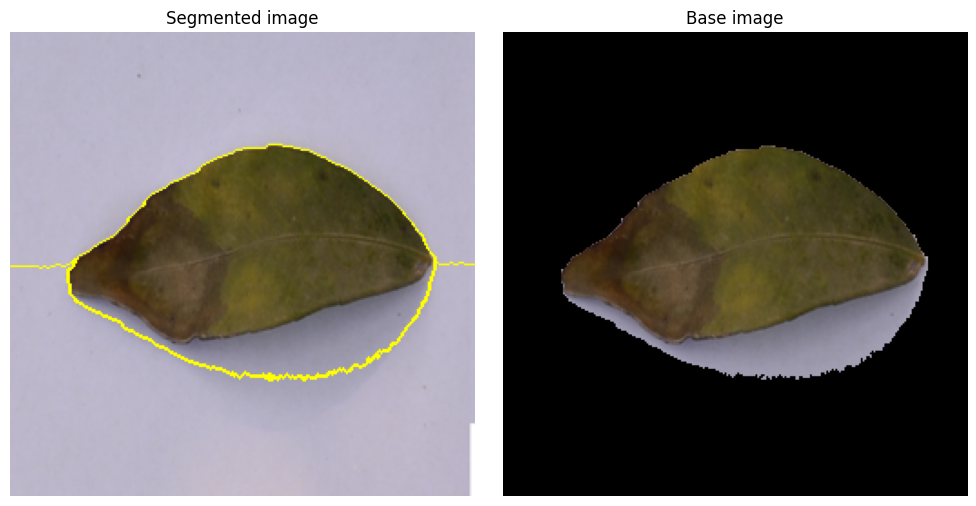

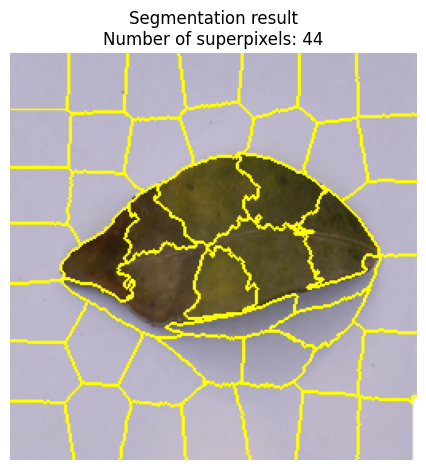

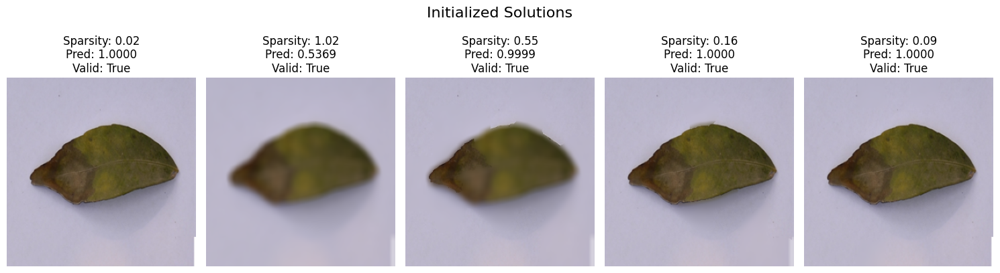

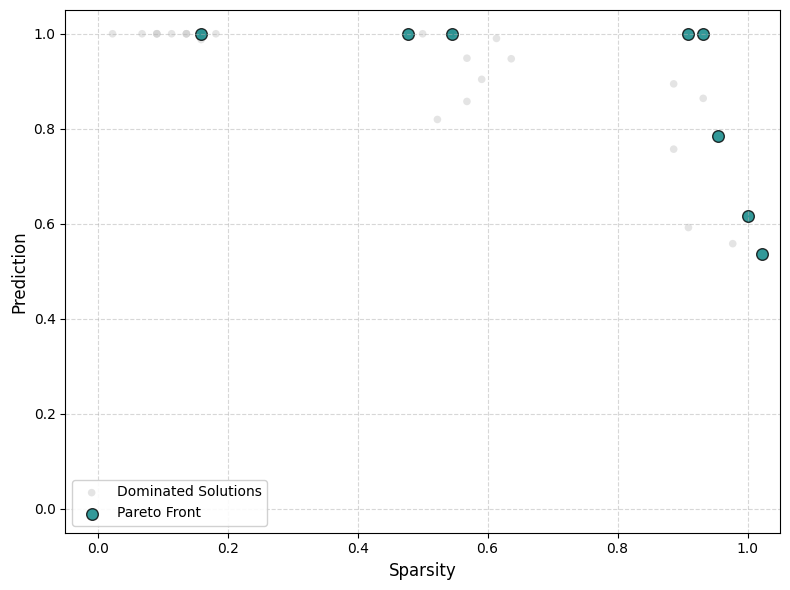

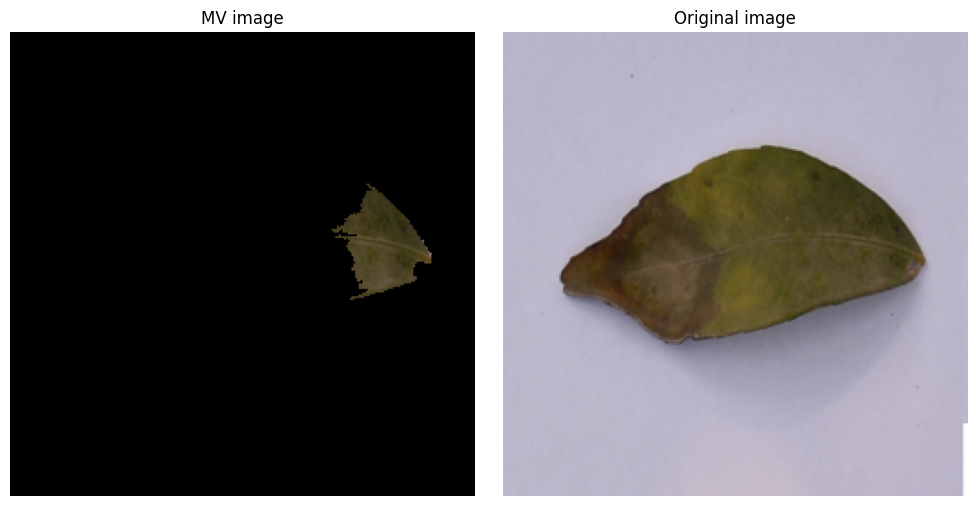


Hypervolume at 1th iteration: 1.0934
New mutation at 10 iteration
Hypervolume at 10th iteration: 1.1158


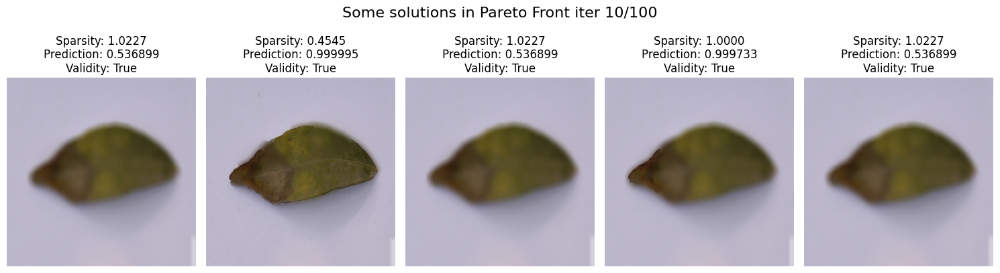

Pareto Front size: 35


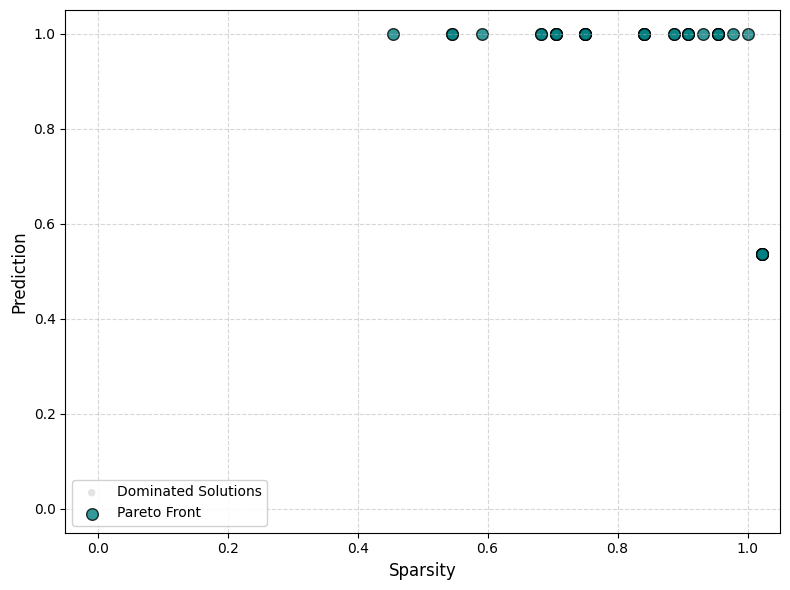

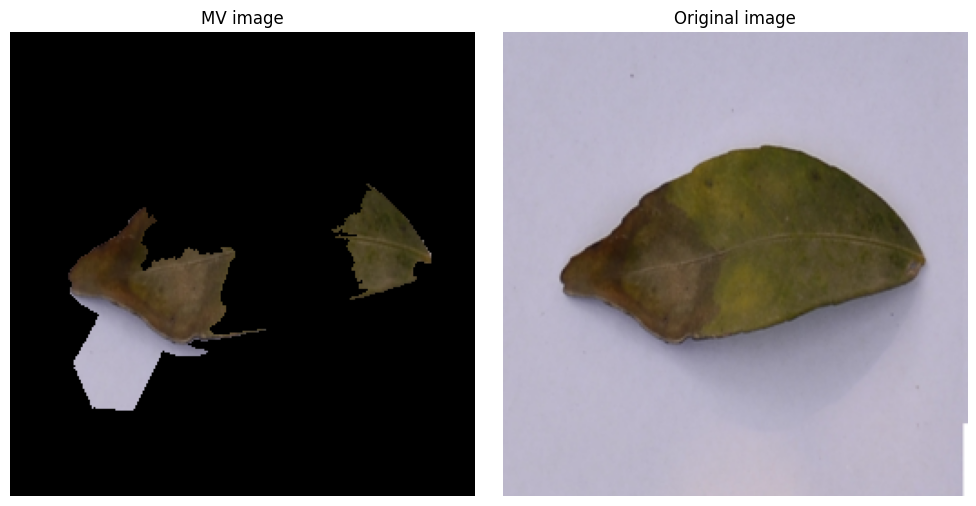


New mutation at 20 iteration
Hypervolume at 20th iteration: 1.1158


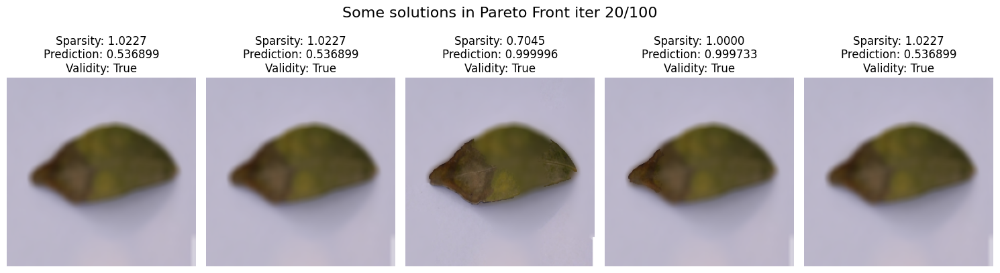

Pareto Front size: 35


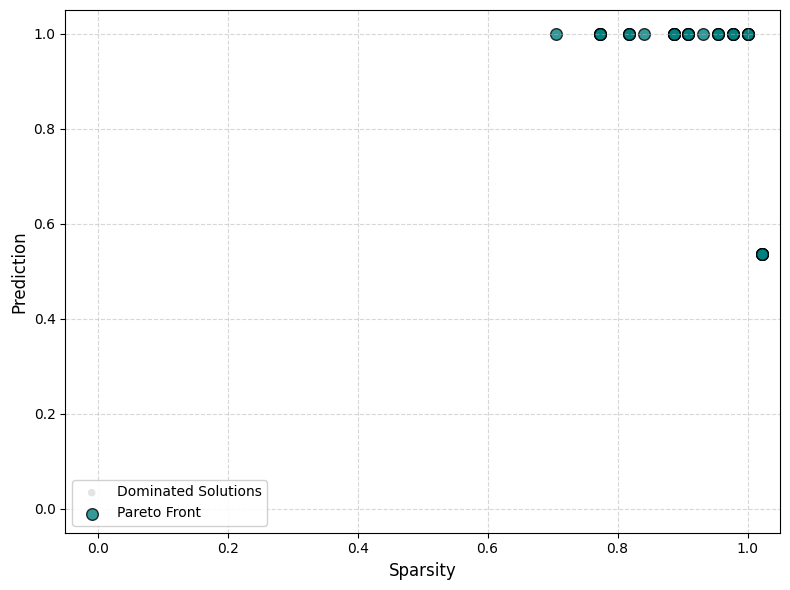

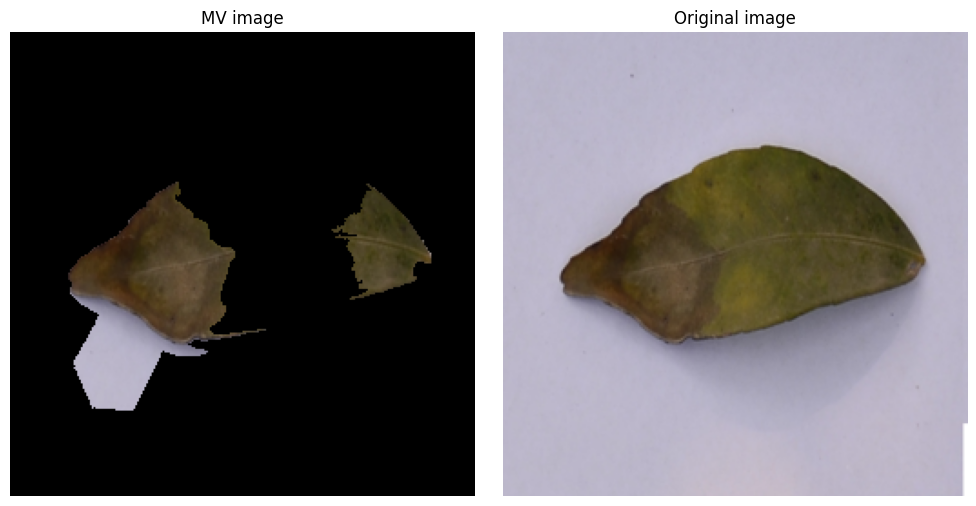


New mutation at 30 iteration
Hypervolume at 30th iteration: 1.1158


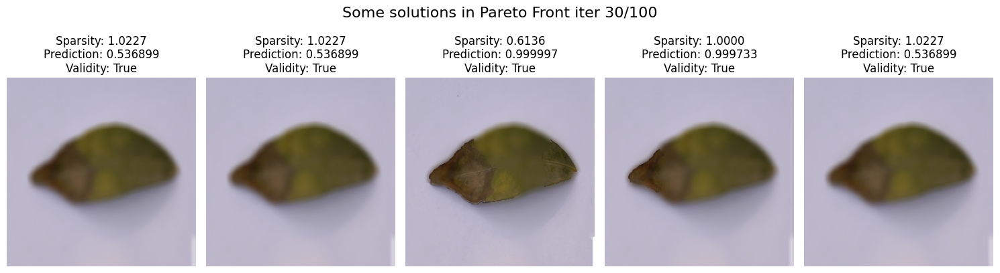

Pareto Front size: 35


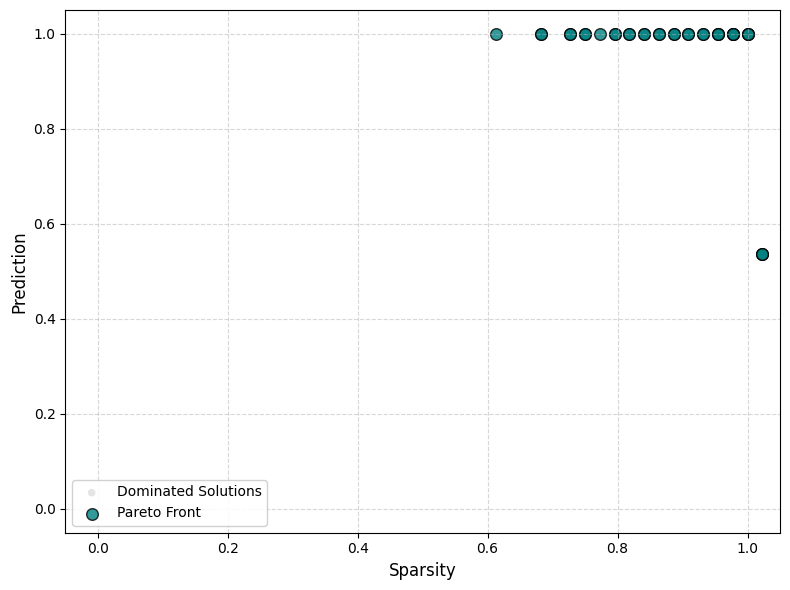

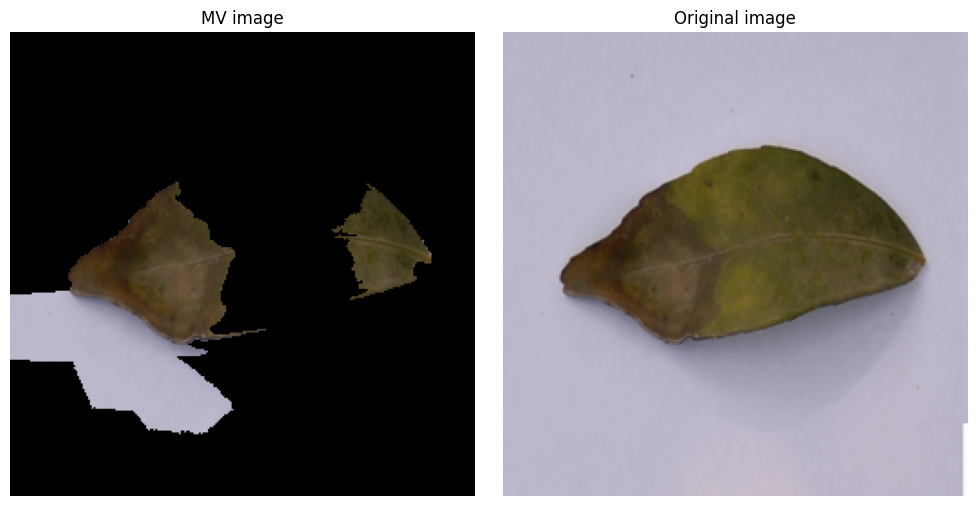


New mutation at 40 iteration
Hypervolume at 40th iteration: 1.1158


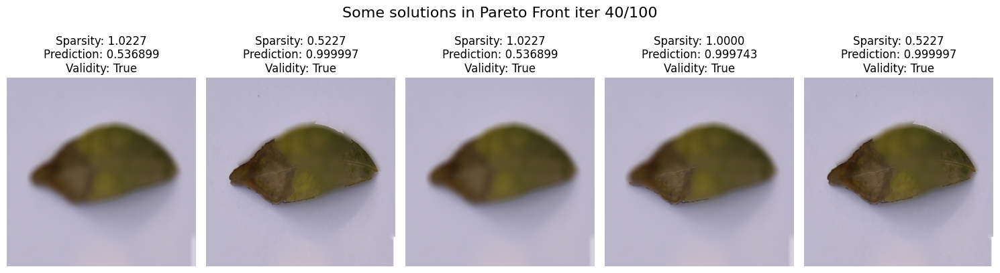

Pareto Front size: 35


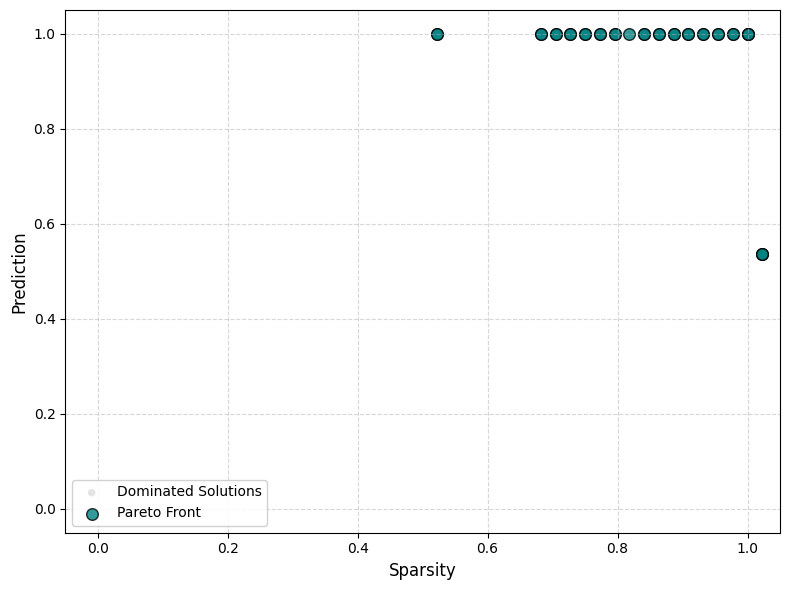

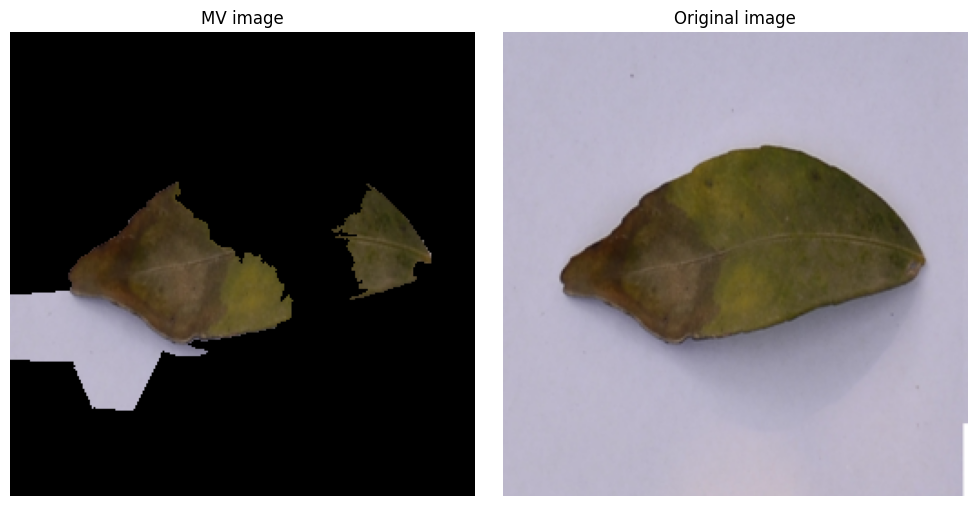


New mutation at 50 iteration
Hypervolume at 50th iteration: 1.1158


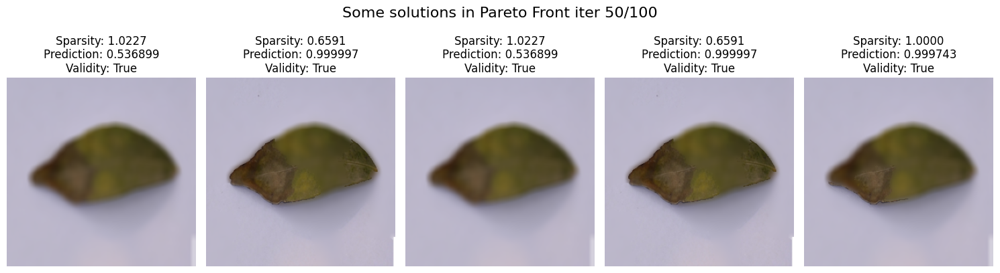

Pareto Front size: 35


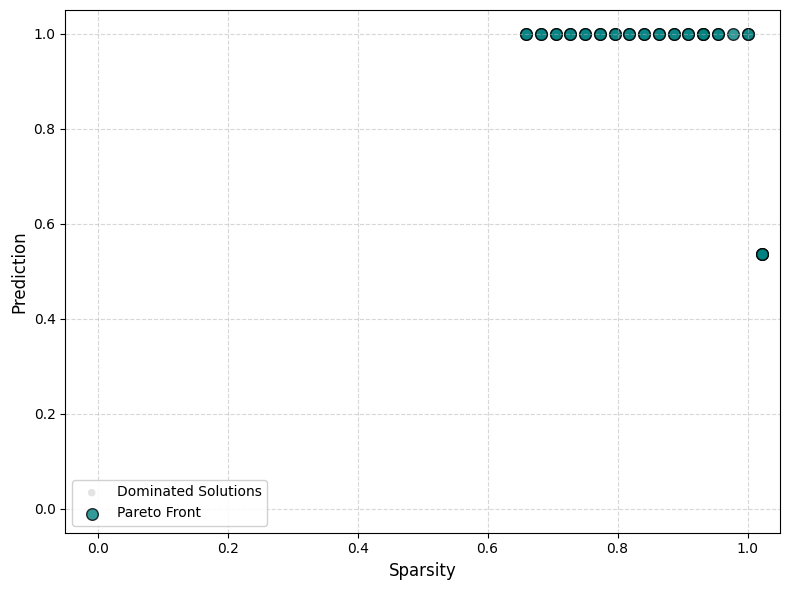

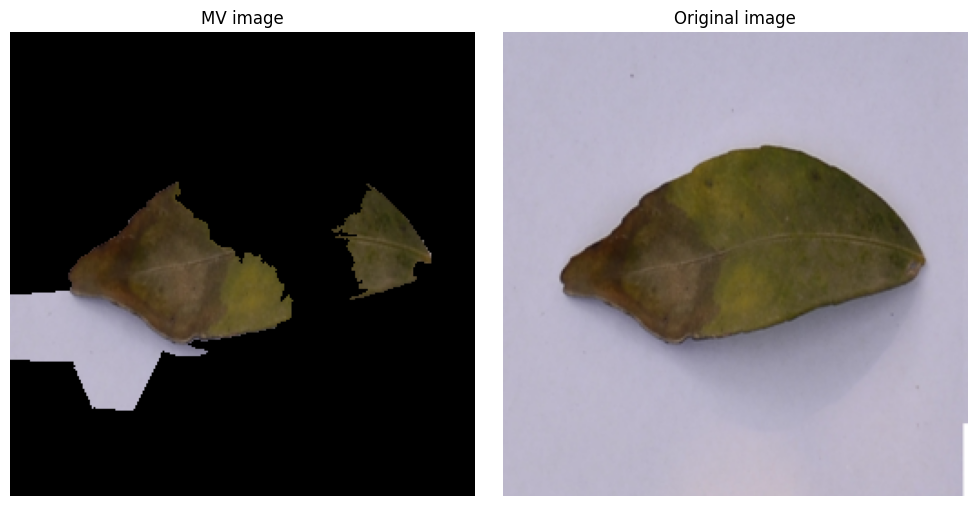


New mutation at 60 iteration
Hypervolume at 60th iteration: 1.1158


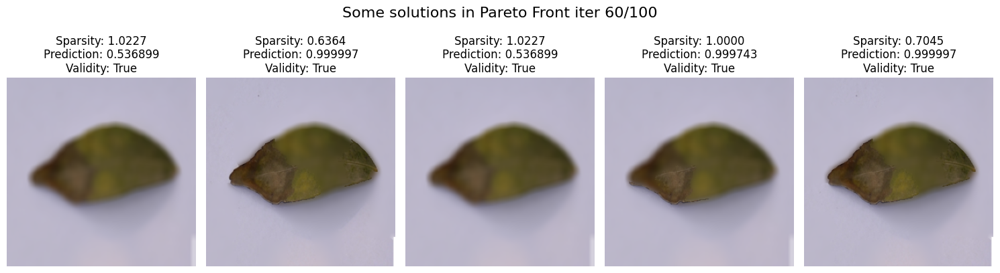

Pareto Front size: 35


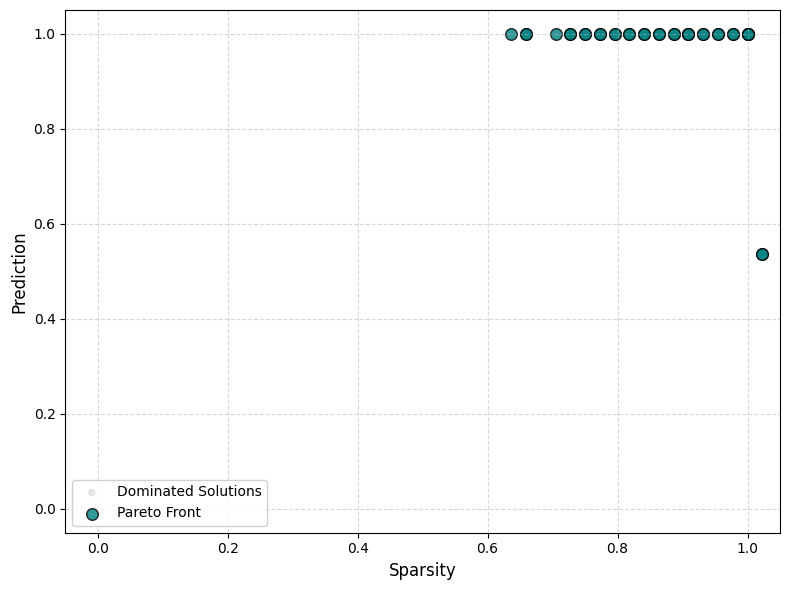

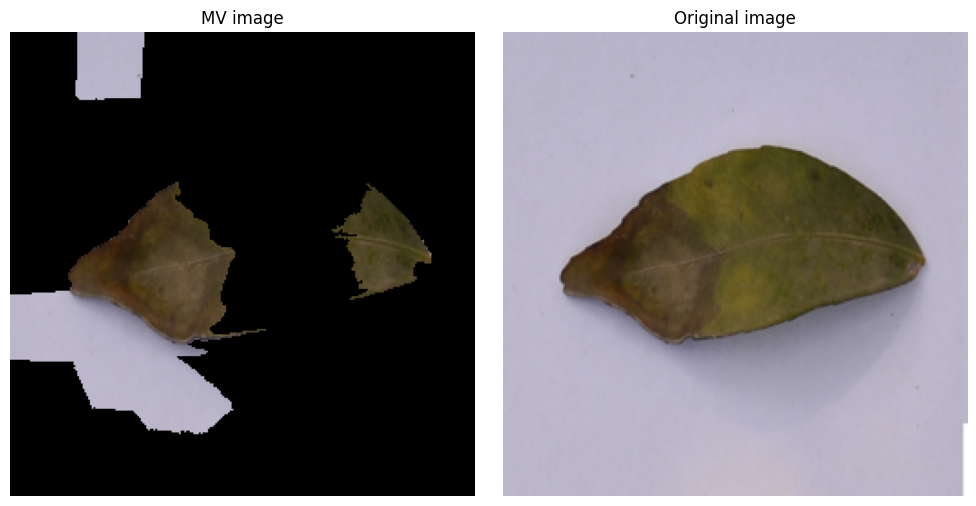


New mutation at 70 iteration
Hypervolume at 70th iteration: 1.1158


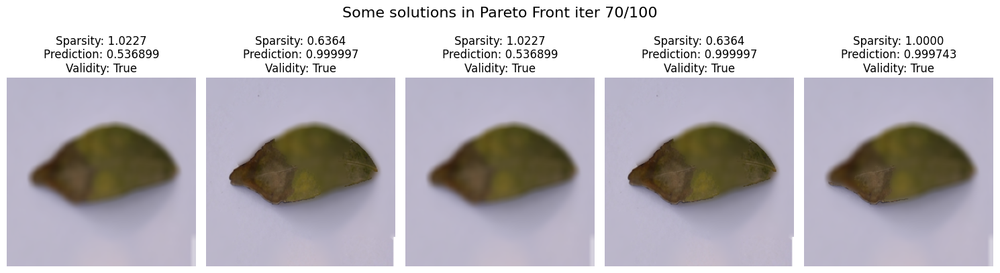

Pareto Front size: 35


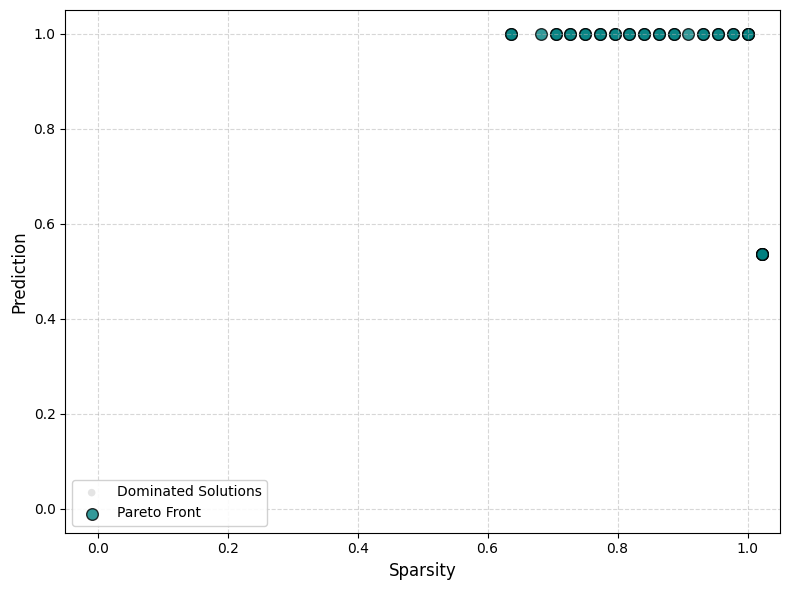

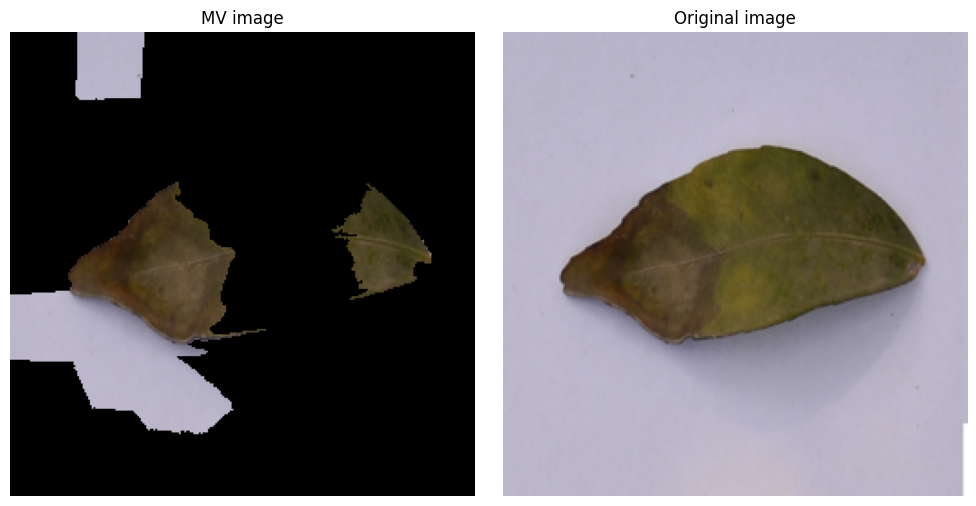


New mutation at 80 iteration
Hypervolume at 80th iteration: 1.1158


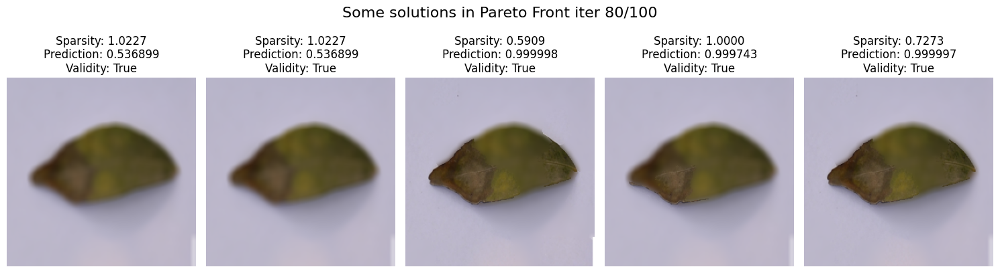

Pareto Front size: 35


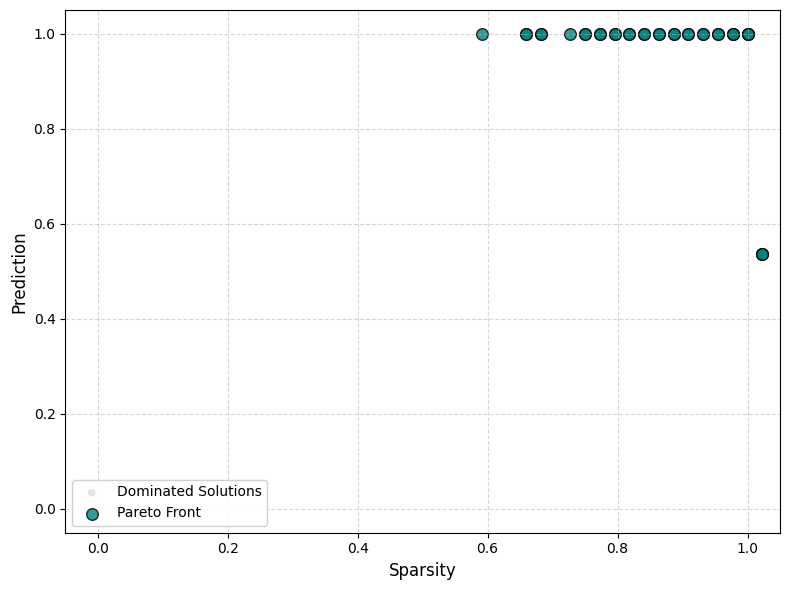

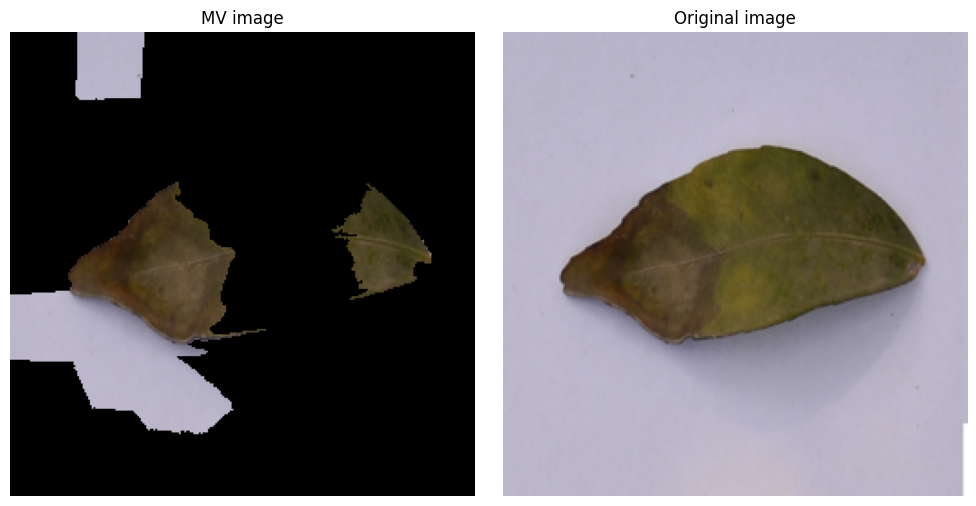


New mutation at 90 iteration
Hypervolume at 90th iteration: 1.1158


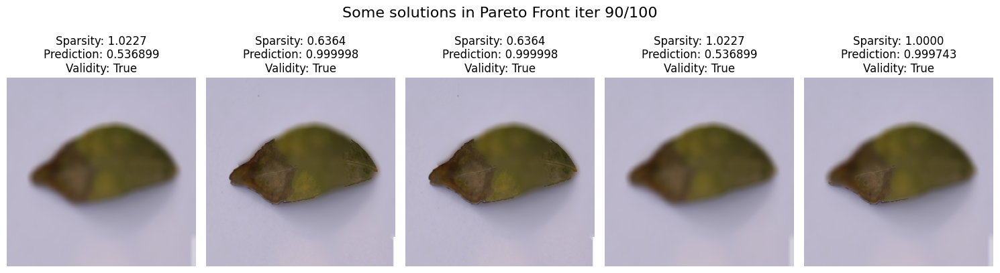

Pareto Front size: 35


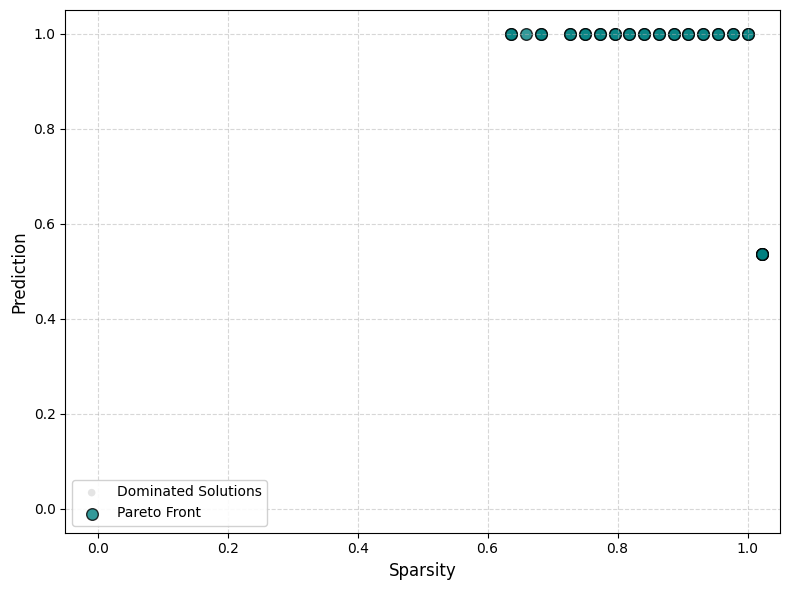

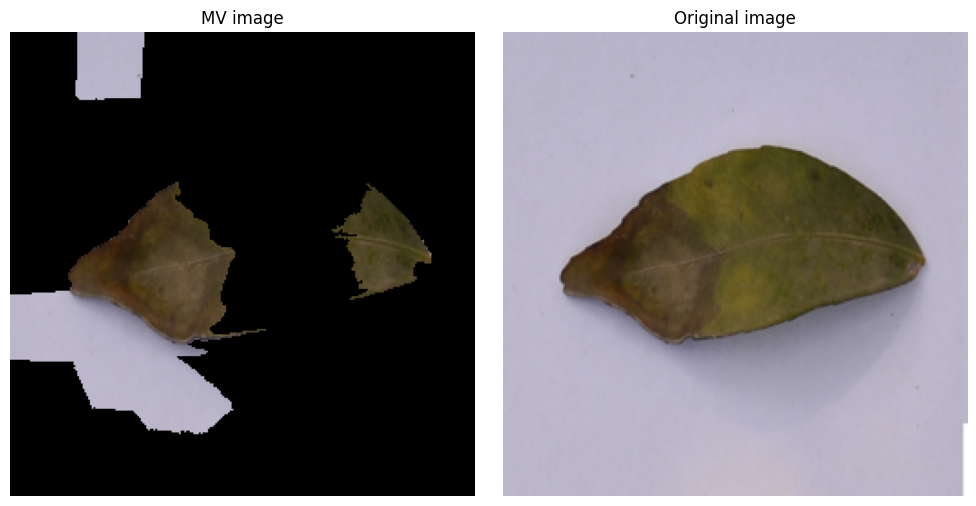


New mutation at 100 iteration
Hypervolume at 100th iteration: 1.1158


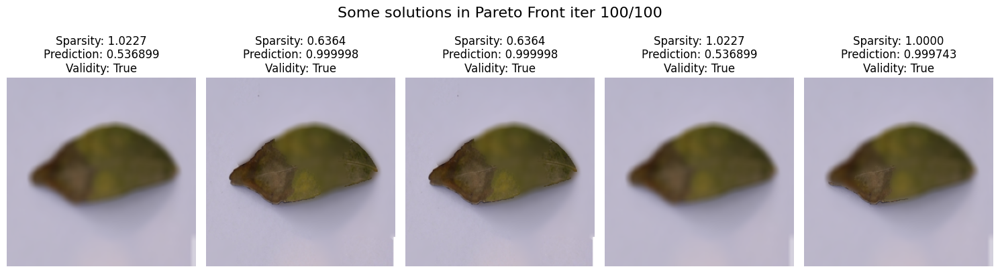

Pareto Front size: 35


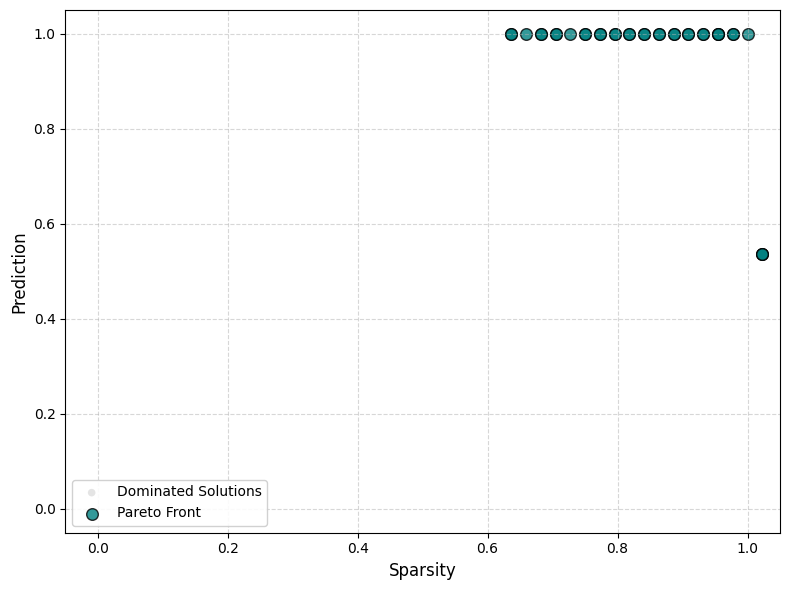

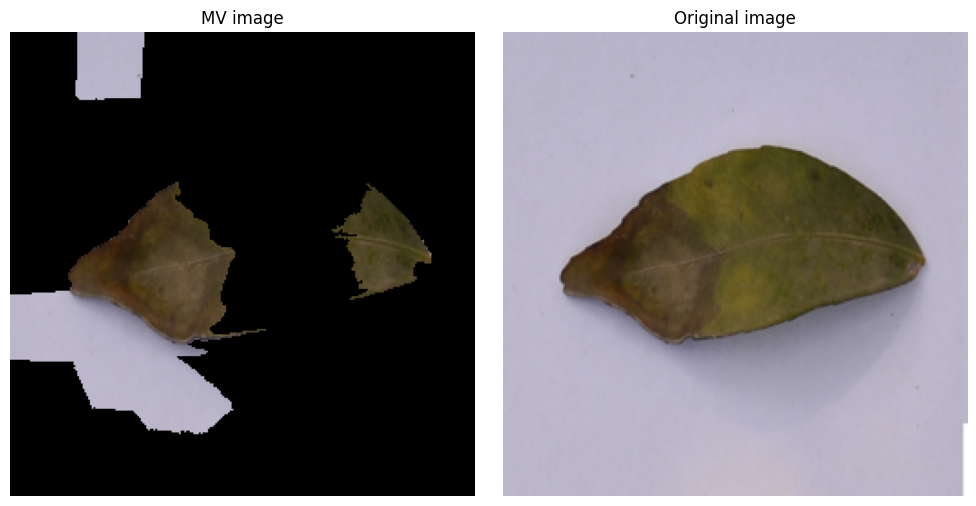

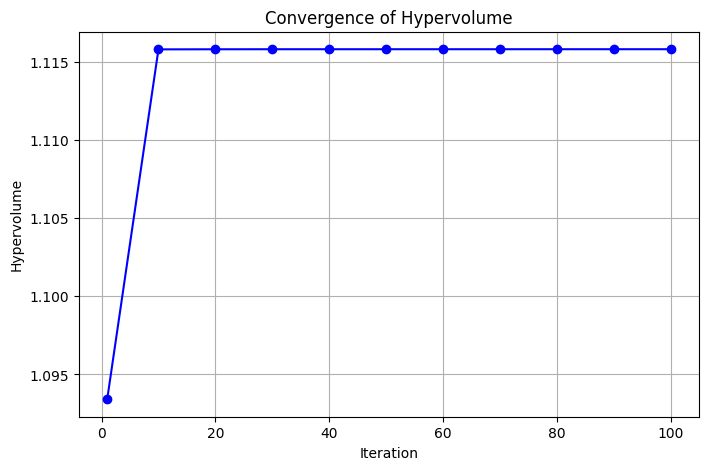

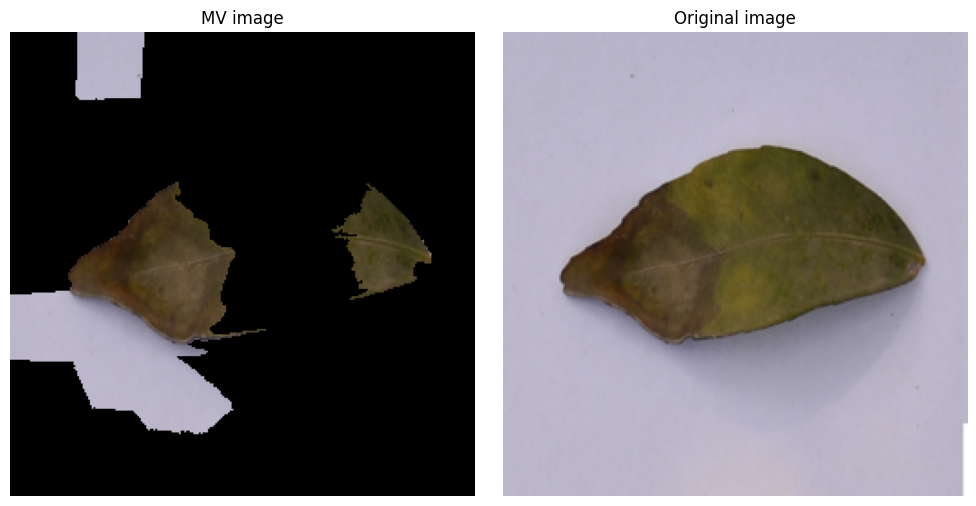

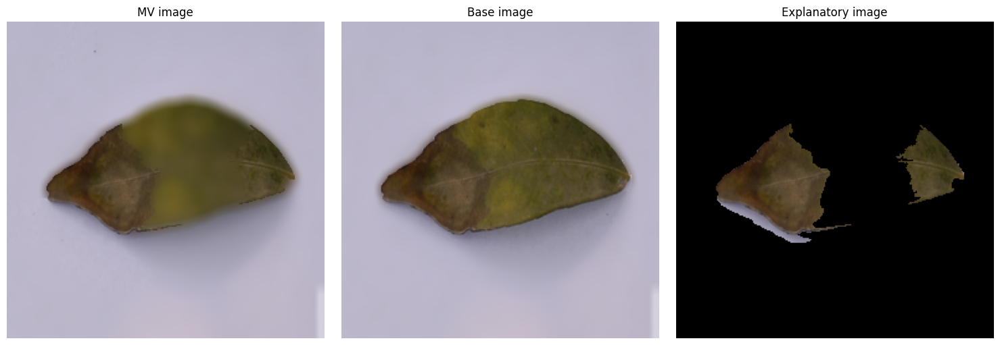

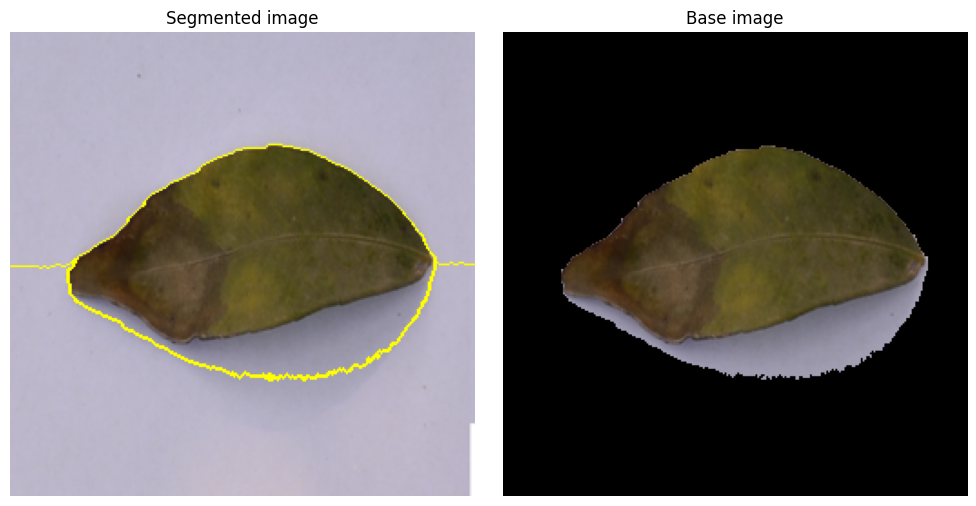

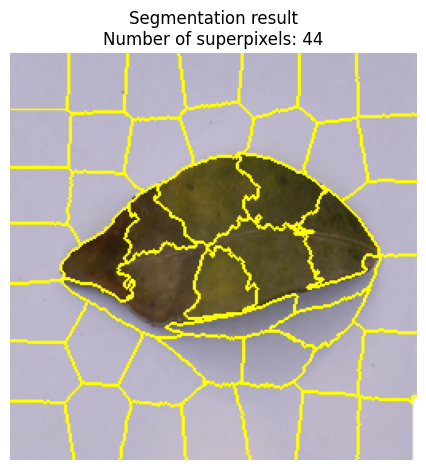

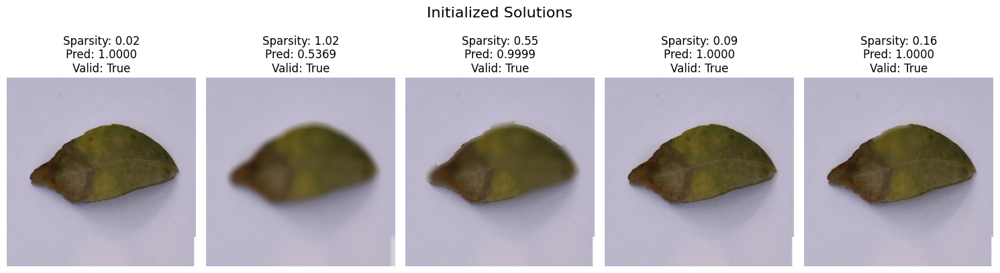

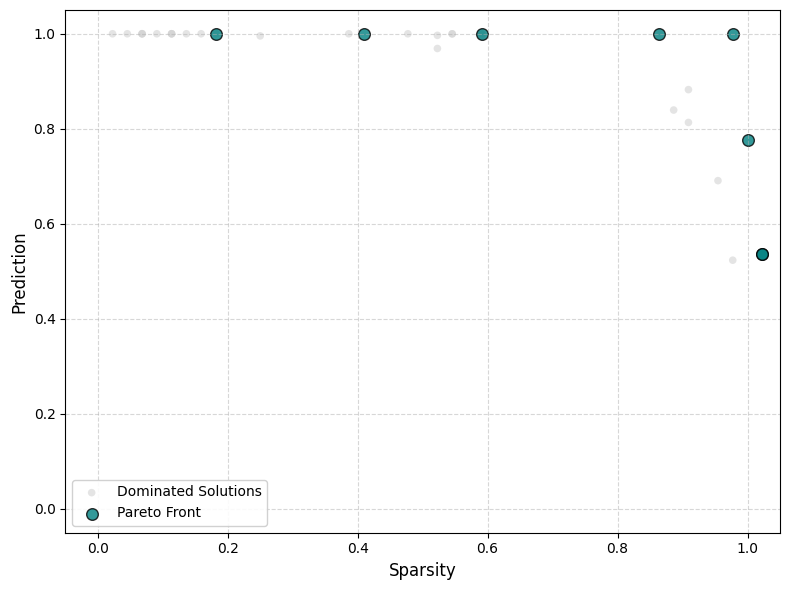

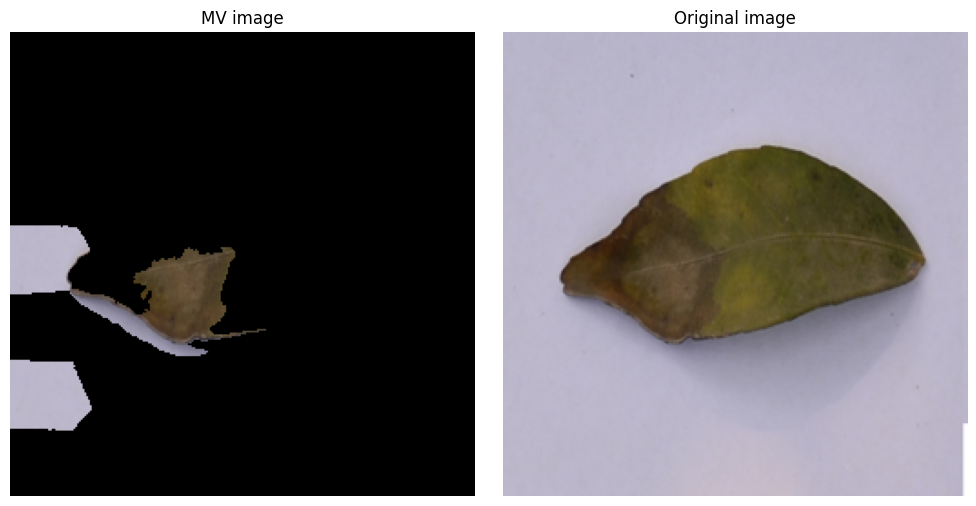


Hypervolume at 1th iteration: 1.1107
New mutation at 10 iteration
Hypervolume at 10th iteration: 1.1158


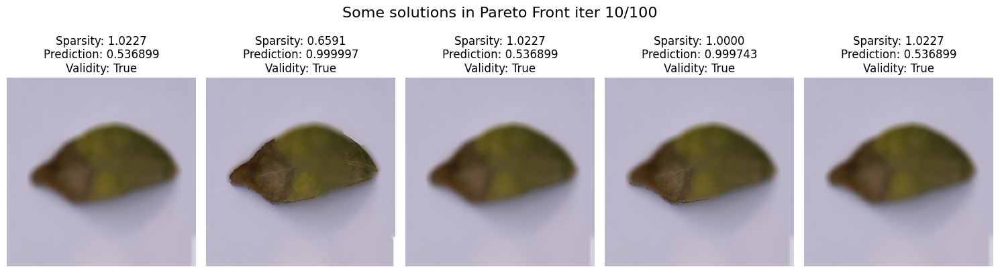

Pareto Front size: 29


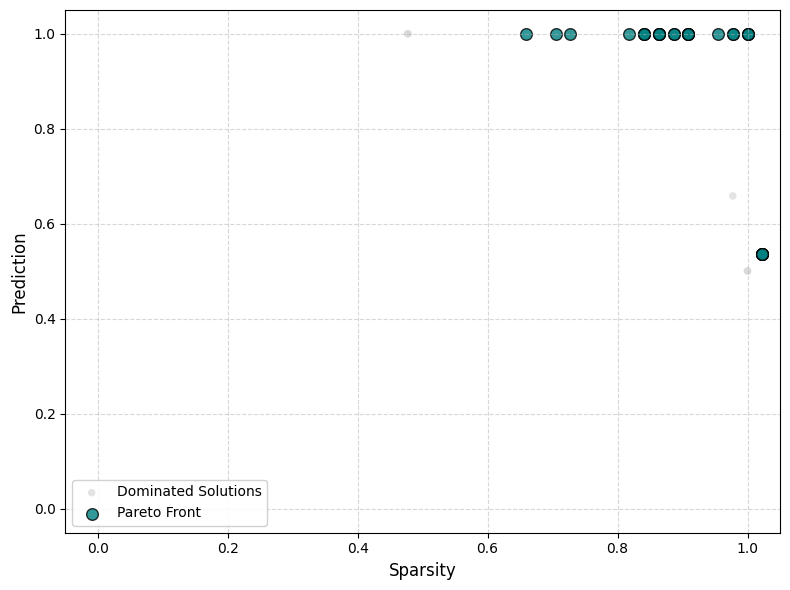

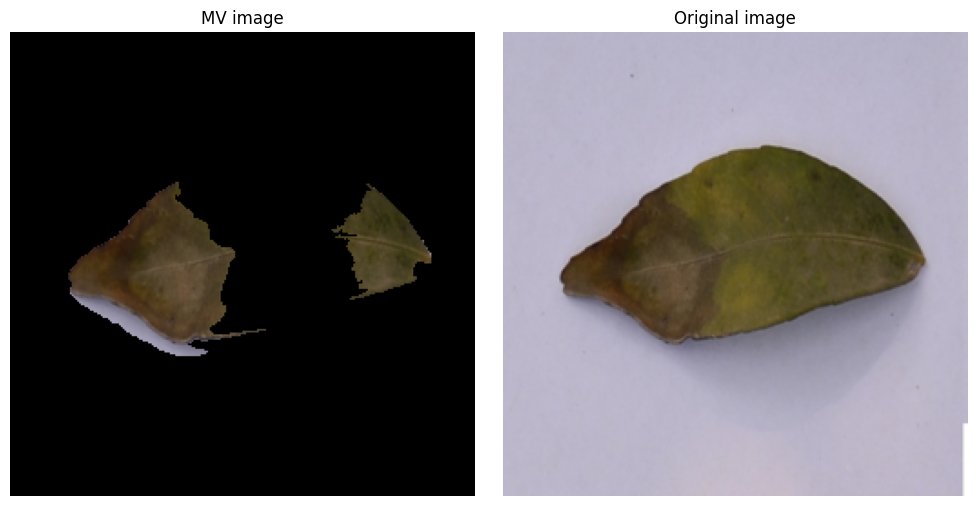


New mutation at 20 iteration
Hypervolume at 20th iteration: 1.1158


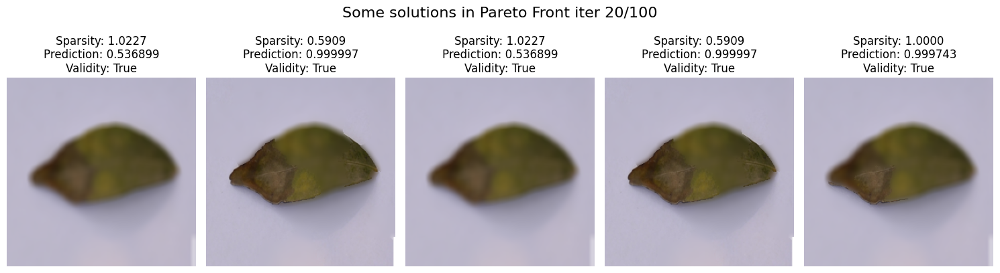

Pareto Front size: 35


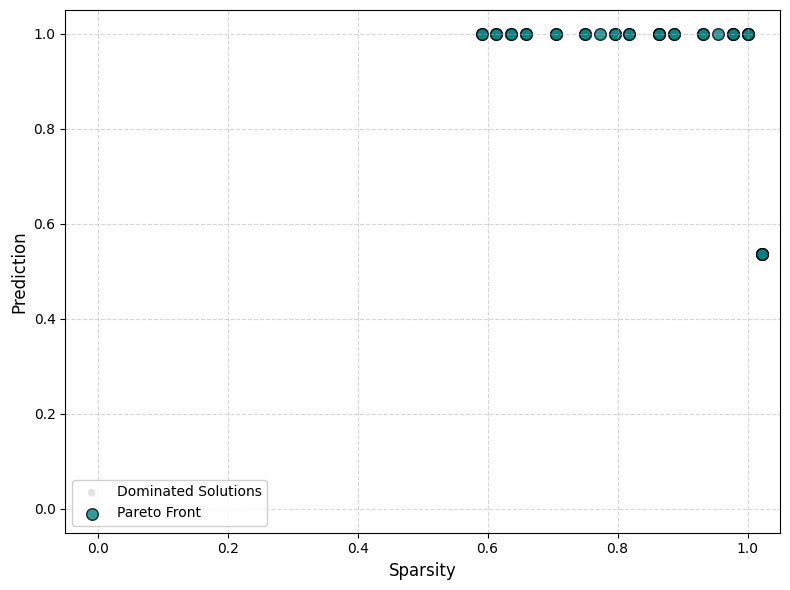

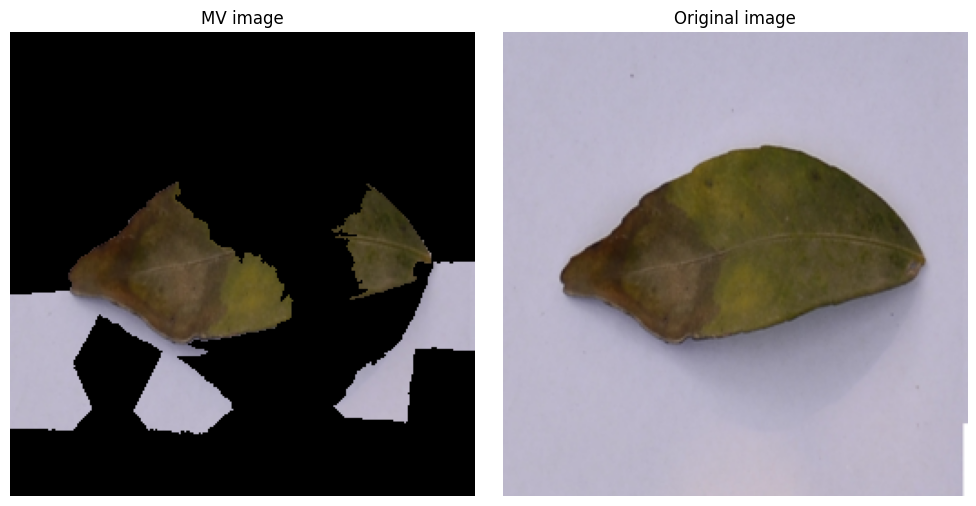


New mutation at 30 iteration
Hypervolume at 30th iteration: 1.1158


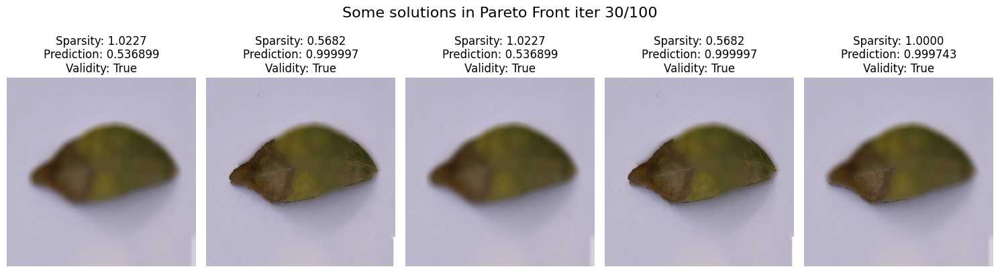

Pareto Front size: 35


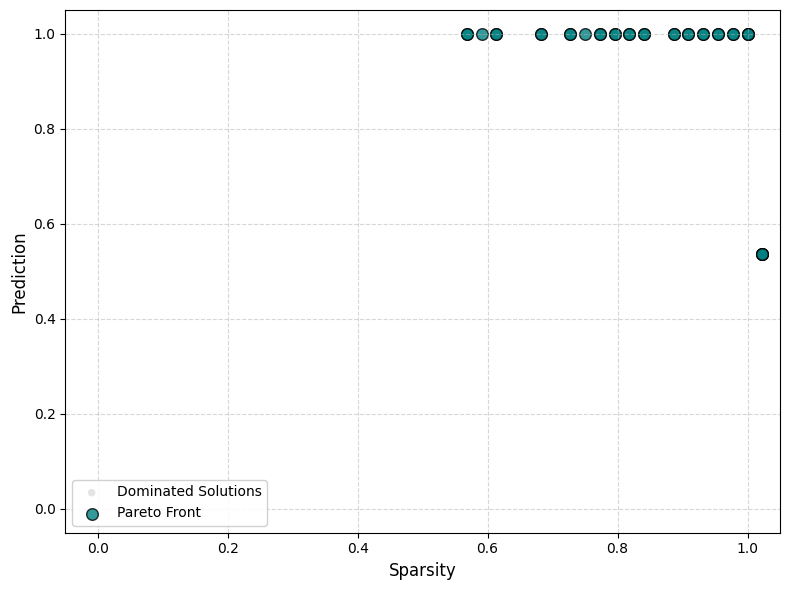

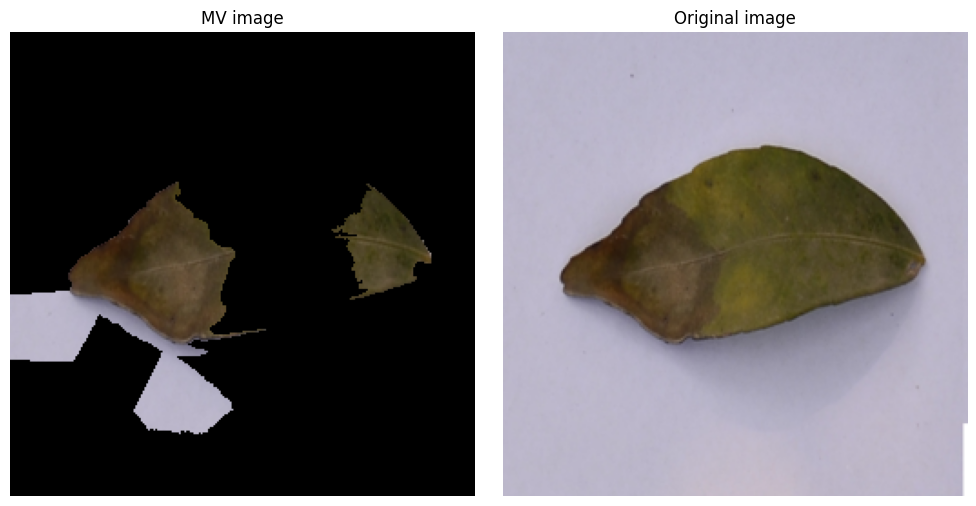


New mutation at 40 iteration
Hypervolume at 40th iteration: 1.1158


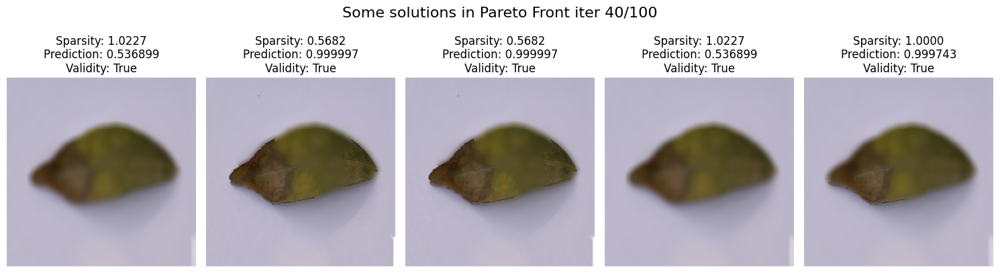

Pareto Front size: 35


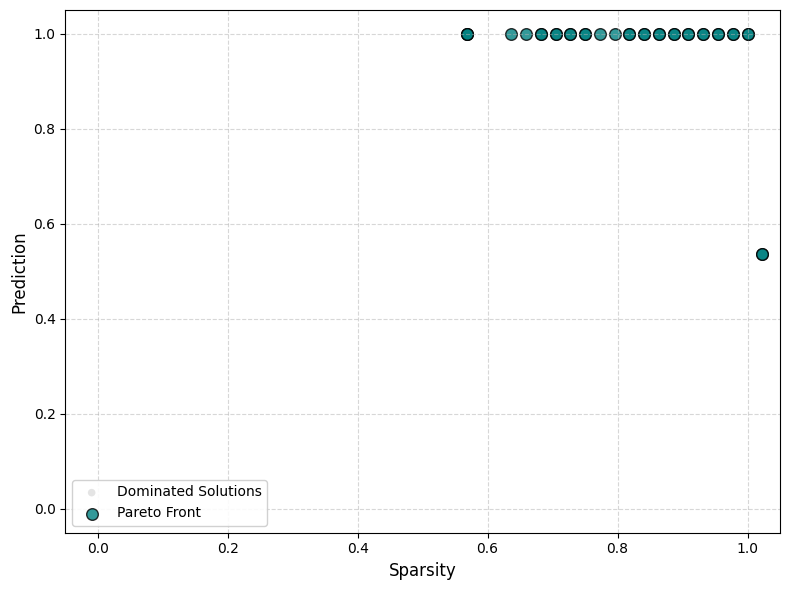

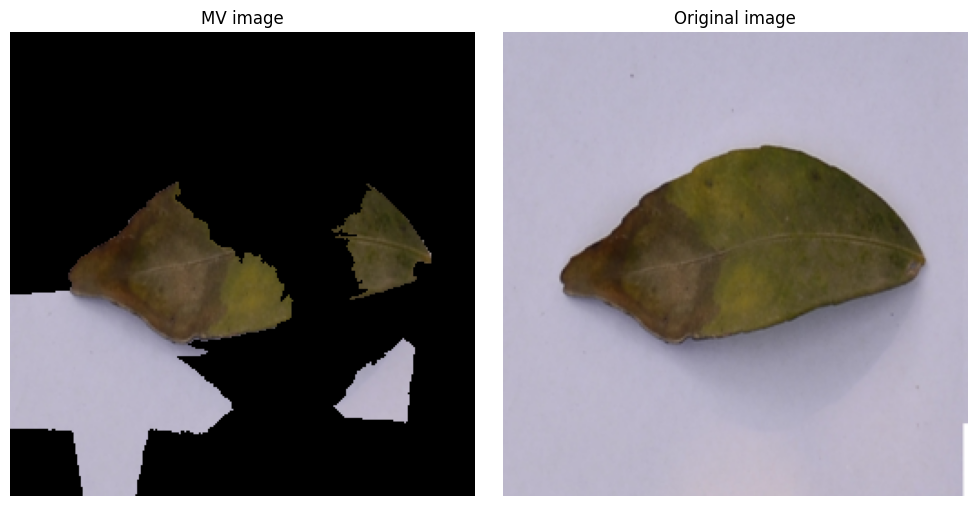


New mutation at 50 iteration
Hypervolume at 50th iteration: 1.1158


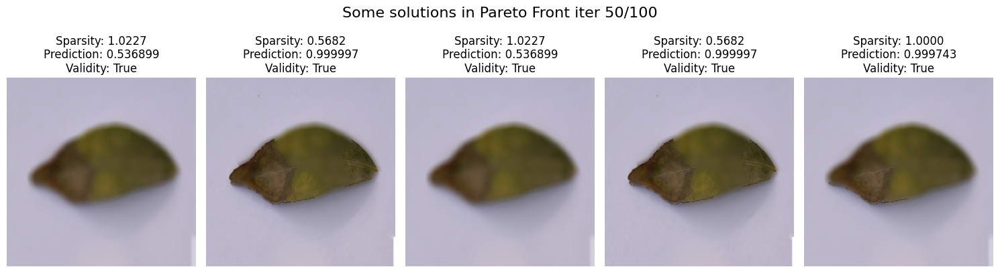

Pareto Front size: 35


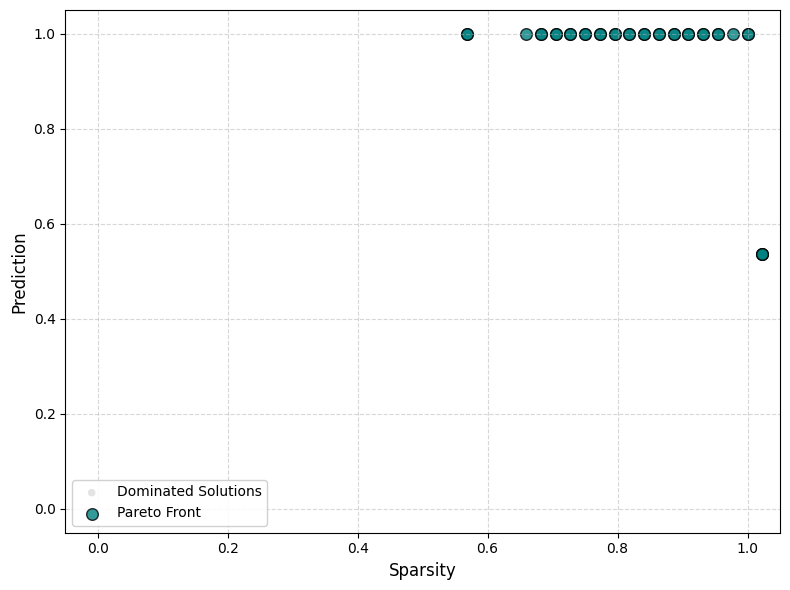

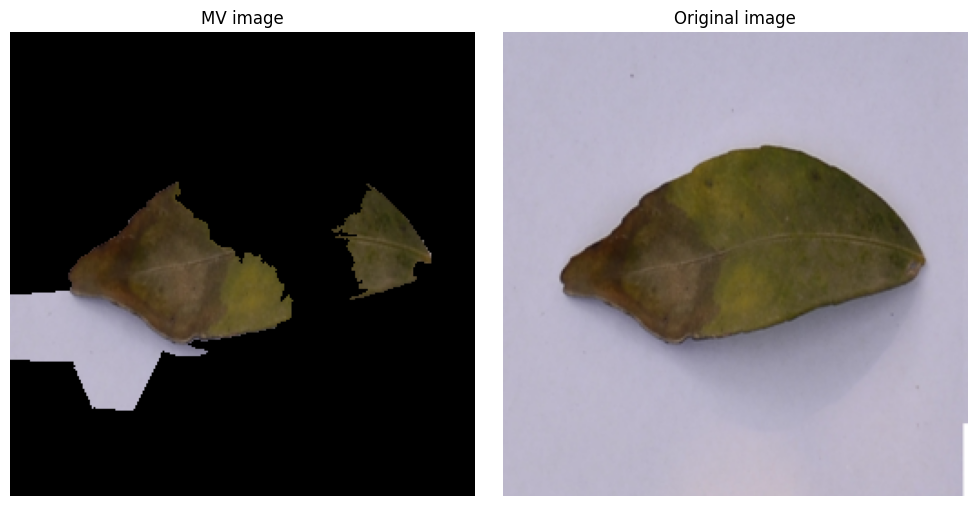


New mutation at 60 iteration
Hypervolume at 60th iteration: 1.1158


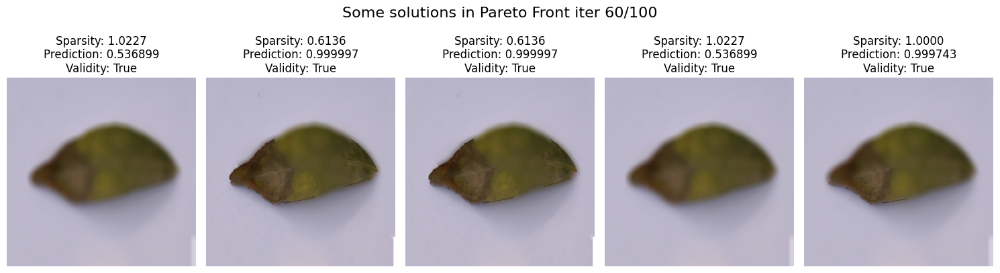

Pareto Front size: 35


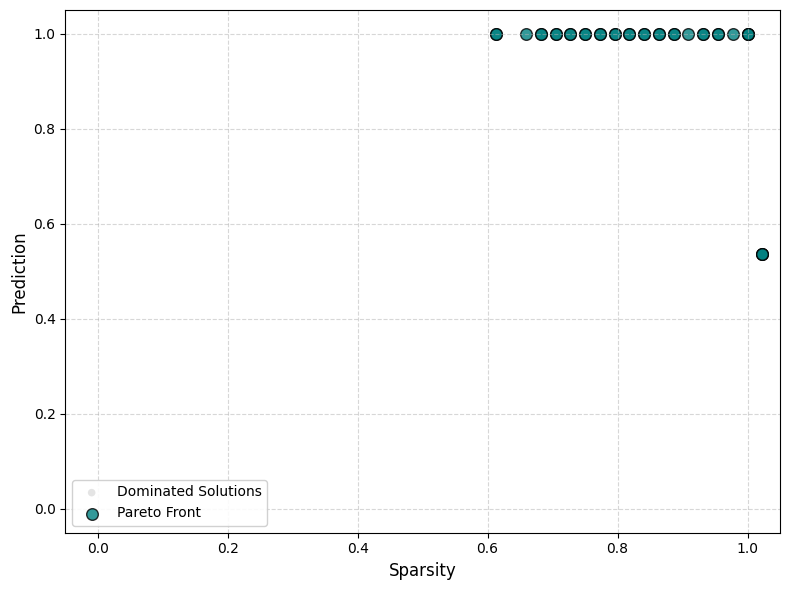

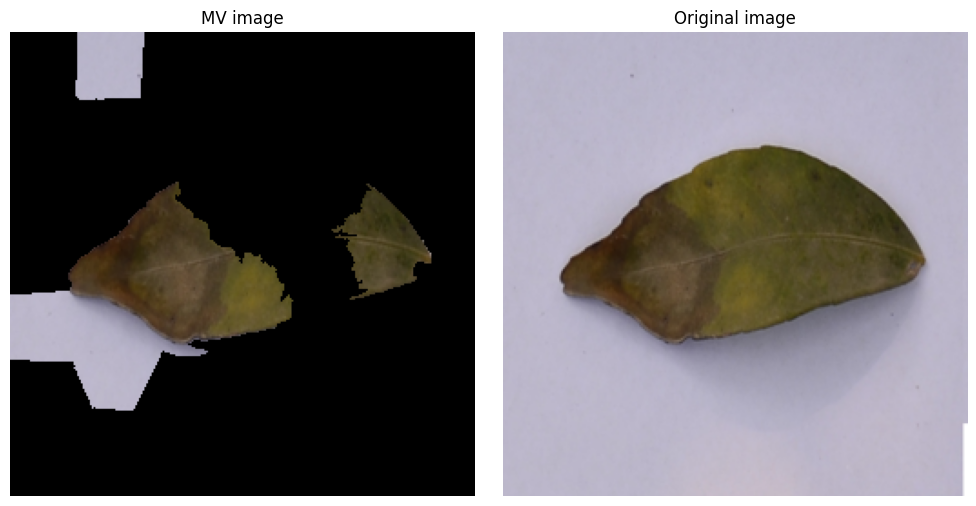


New mutation at 70 iteration
Hypervolume at 70th iteration: 1.1158


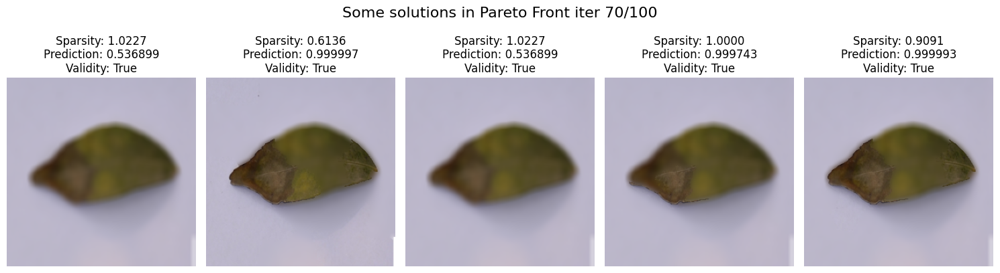

Pareto Front size: 35


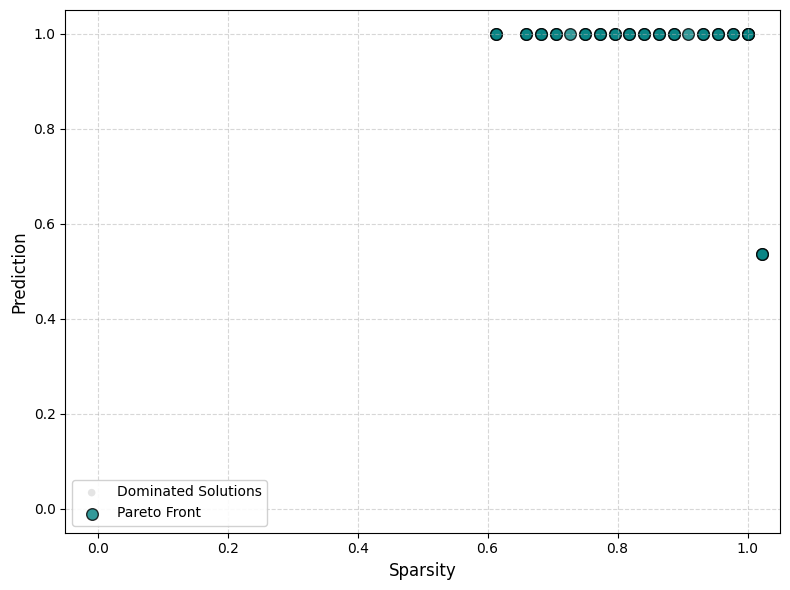

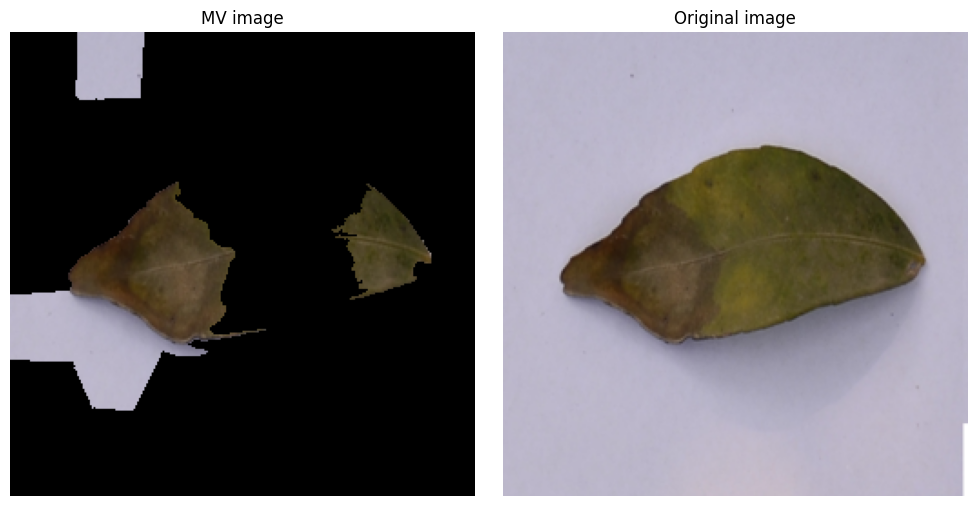


New mutation at 80 iteration
Hypervolume at 80th iteration: 1.1158


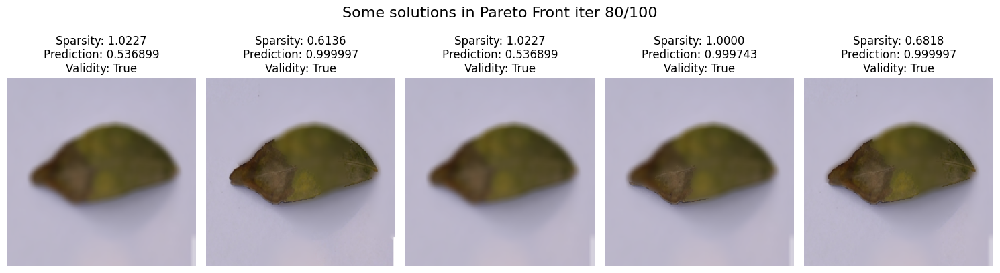

Pareto Front size: 35


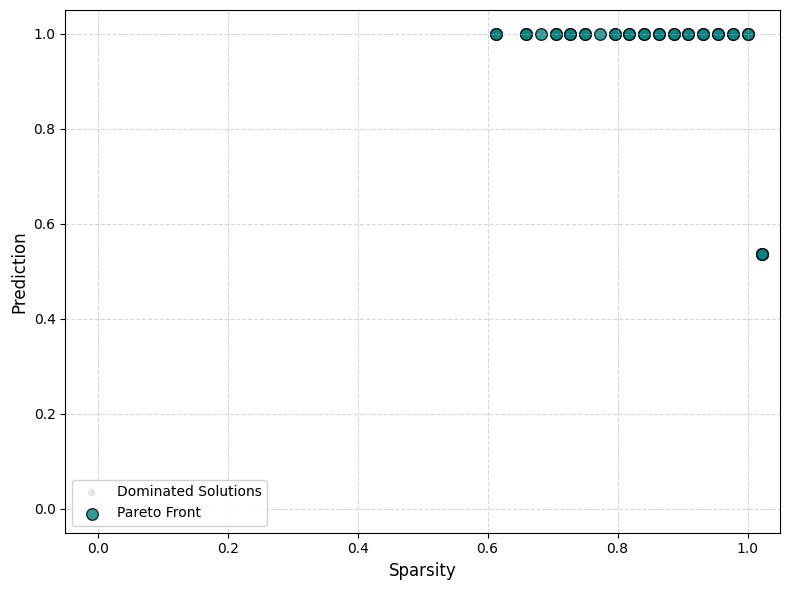

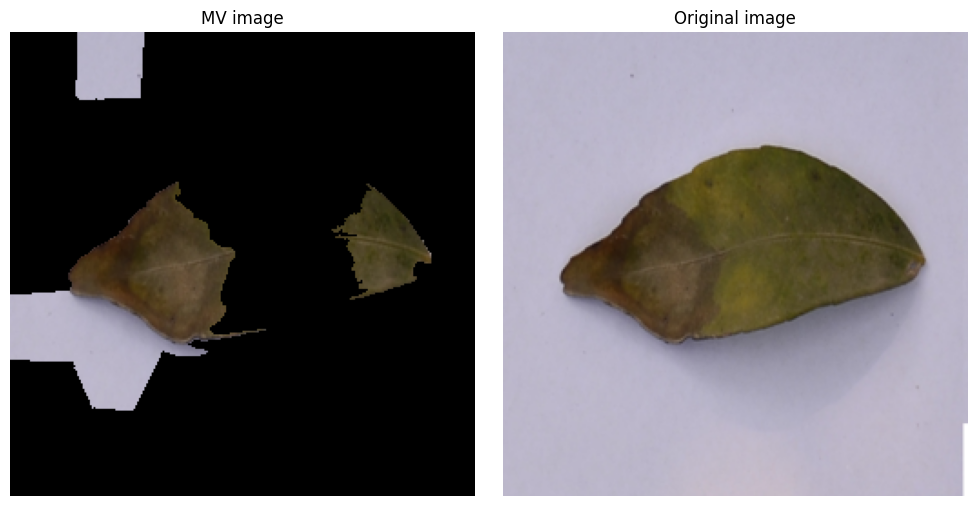


New mutation at 90 iteration
Hypervolume at 90th iteration: 1.1158


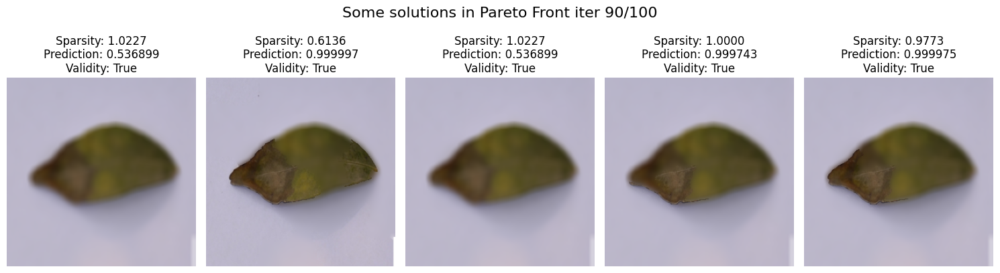

Pareto Front size: 35


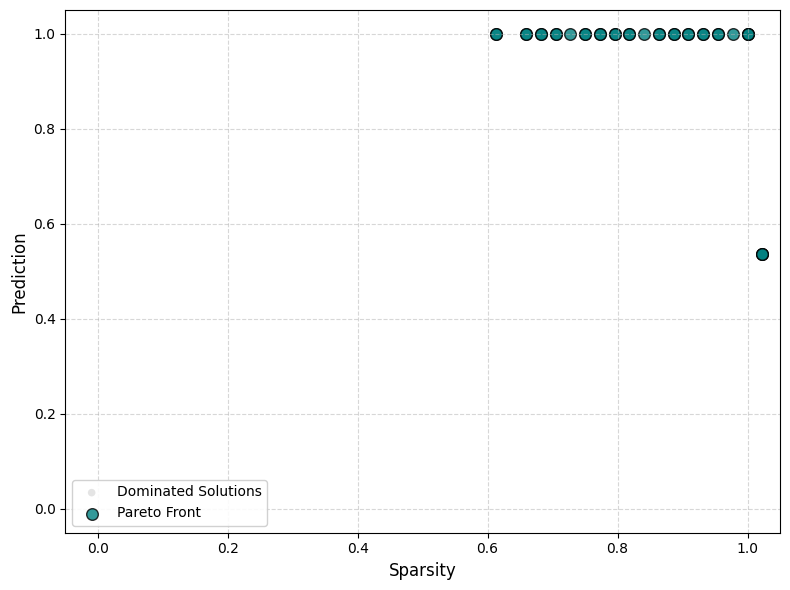

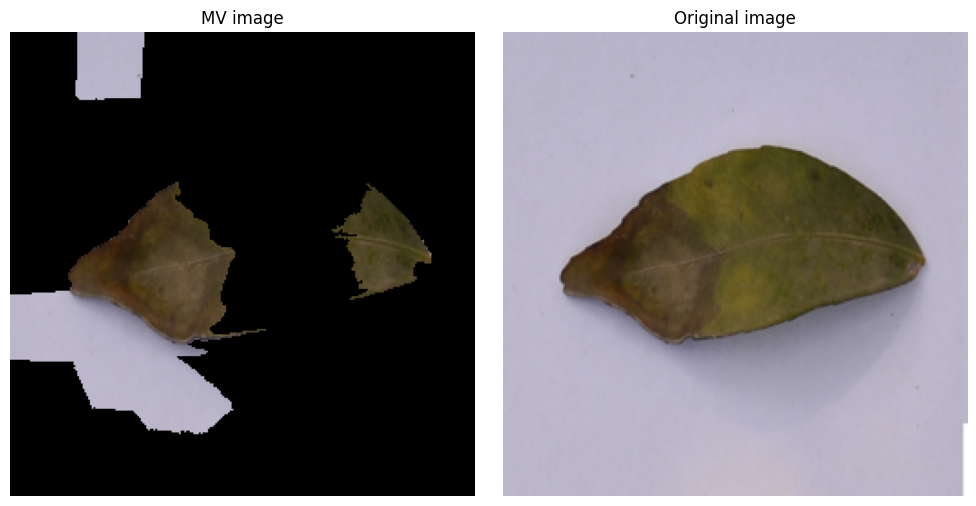


New mutation at 100 iteration
Hypervolume at 100th iteration: 1.1158


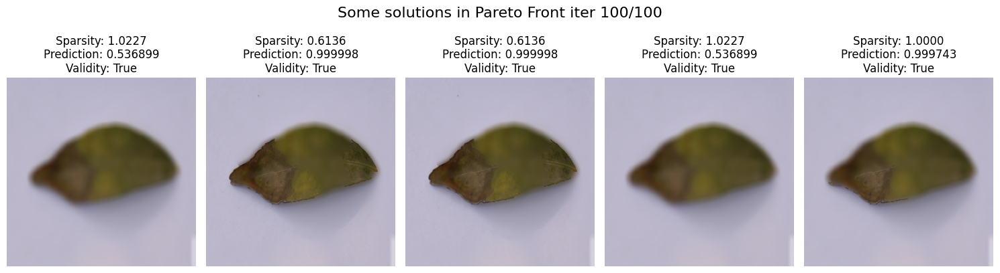

Pareto Front size: 35


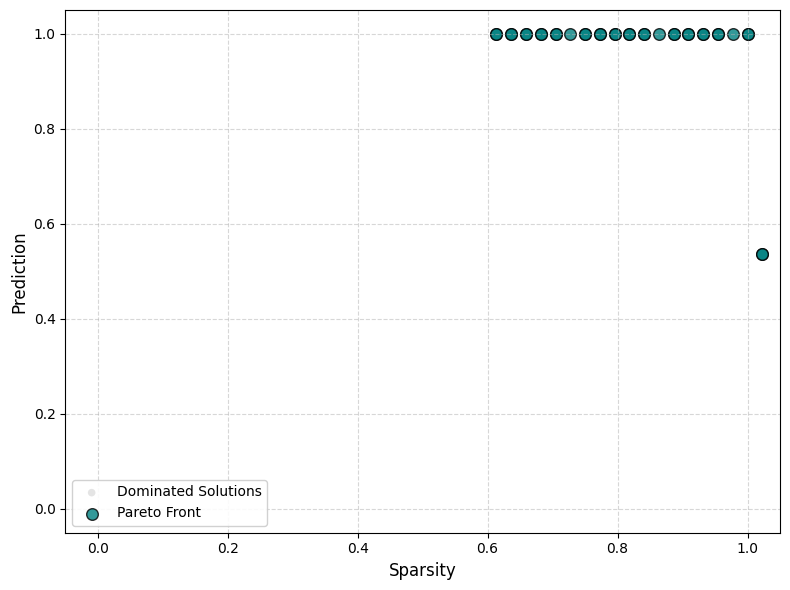

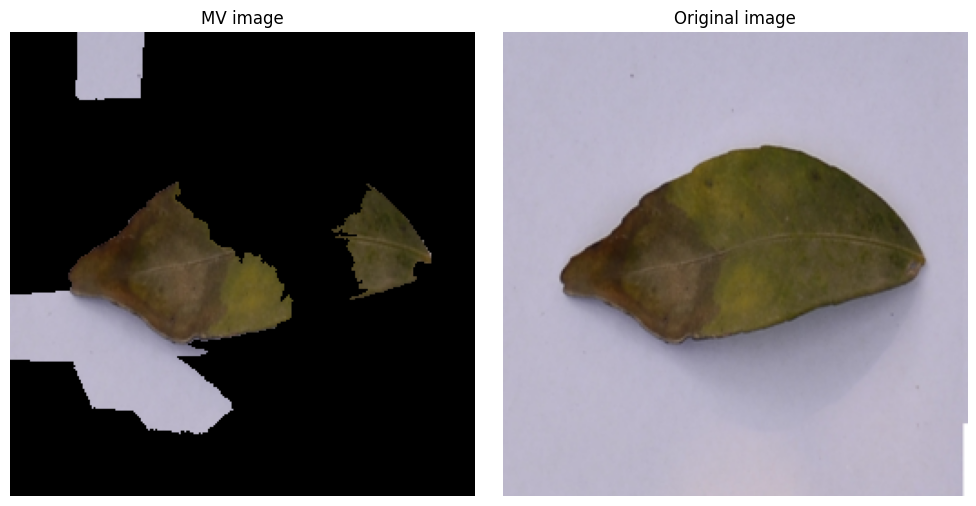

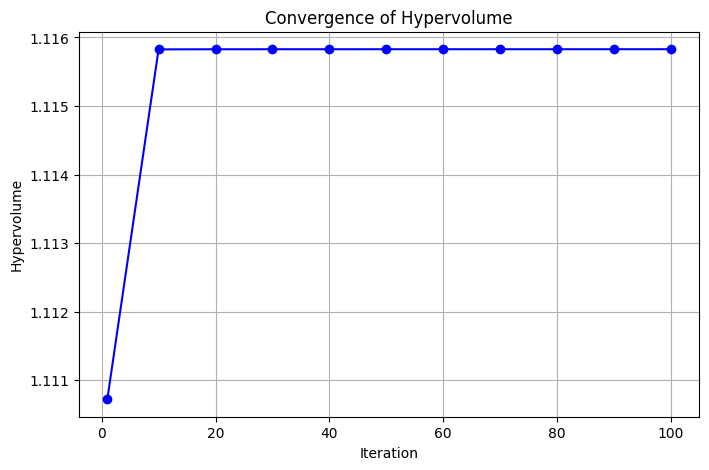

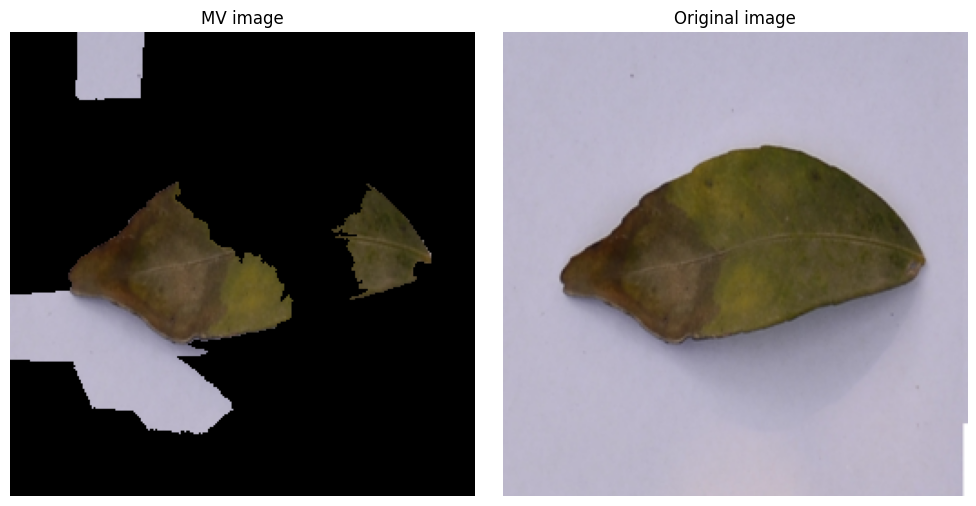

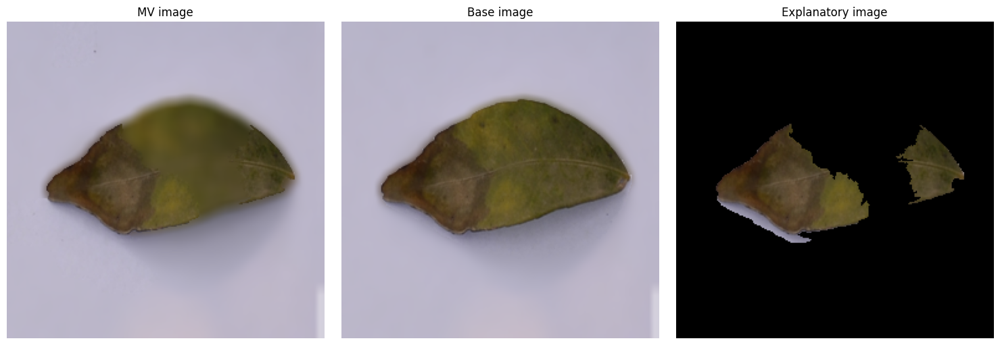

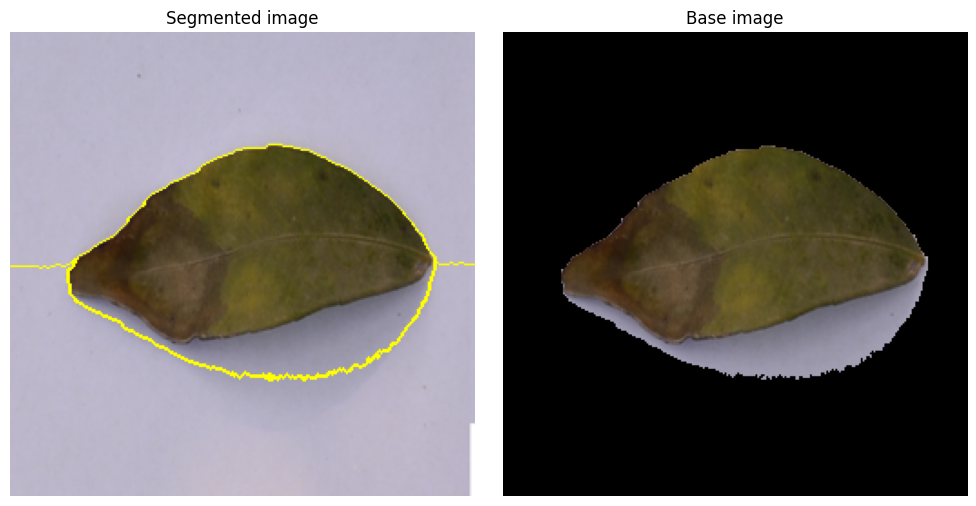

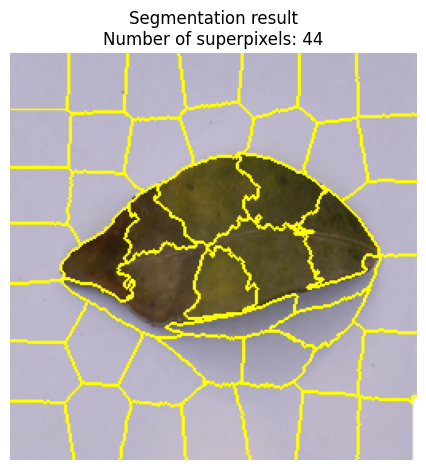

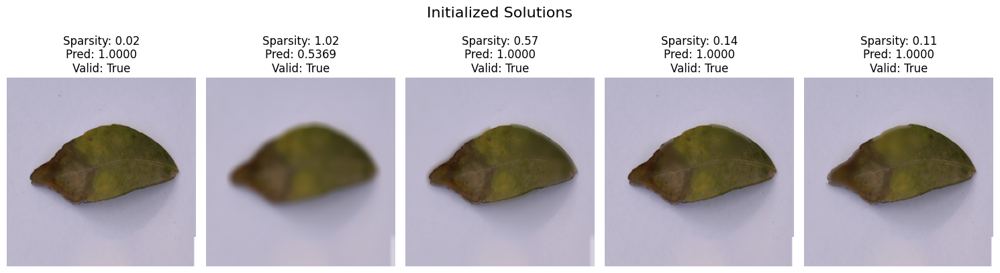

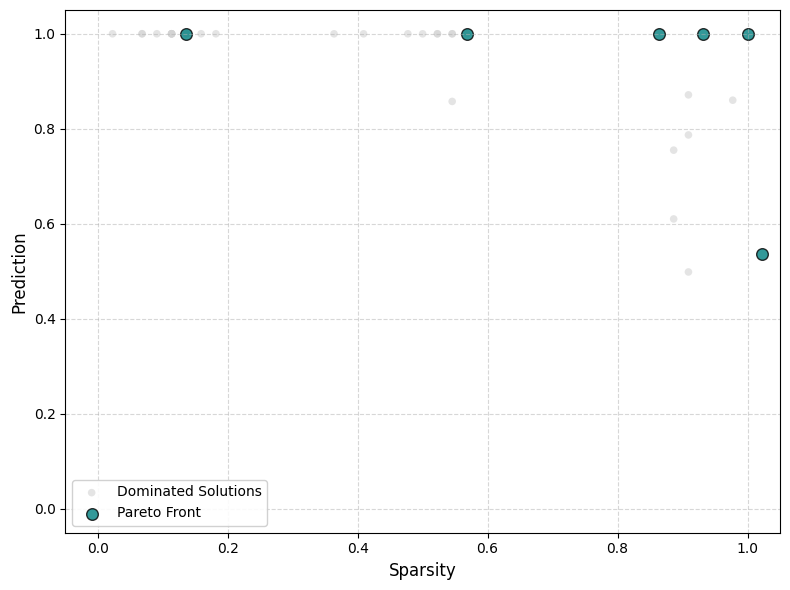

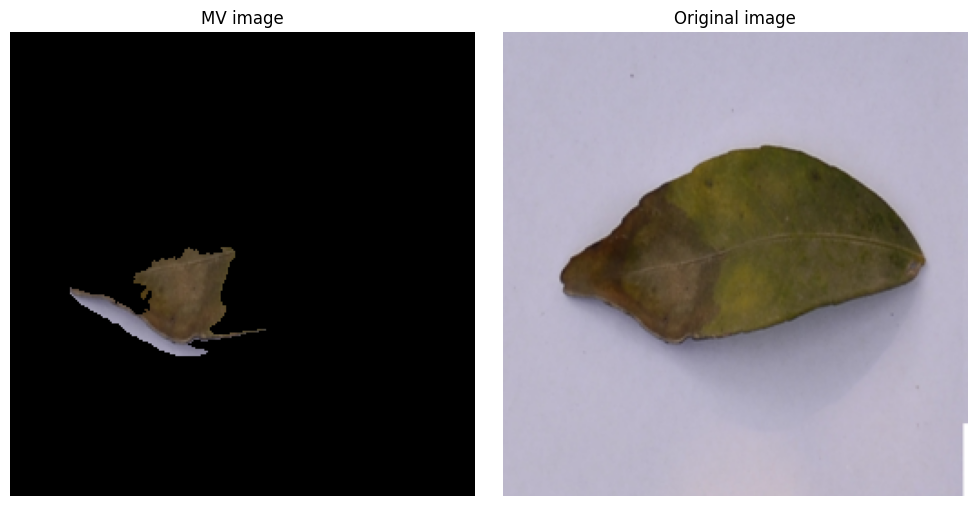


Hypervolume at 1th iteration: 1.1158
New mutation at 10 iteration
Hypervolume at 10th iteration: 1.1158


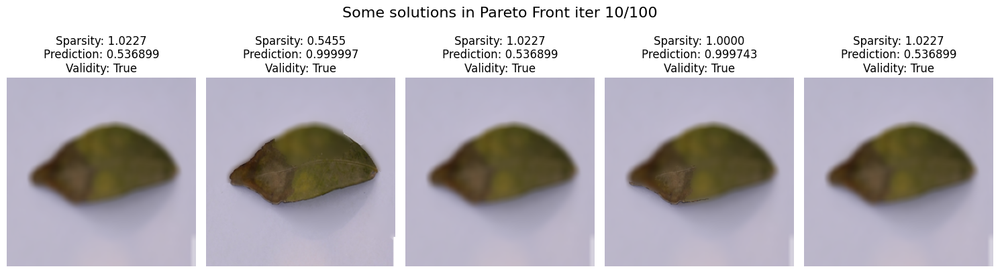

Pareto Front size: 35


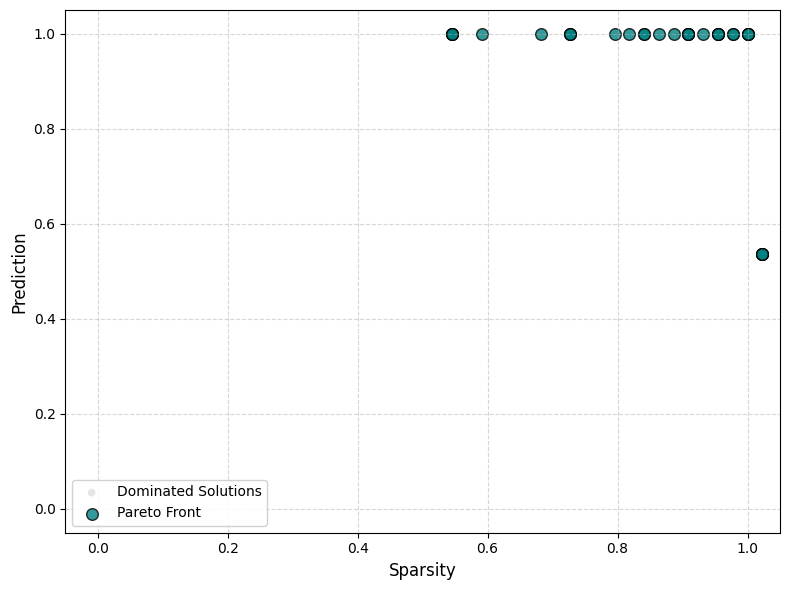

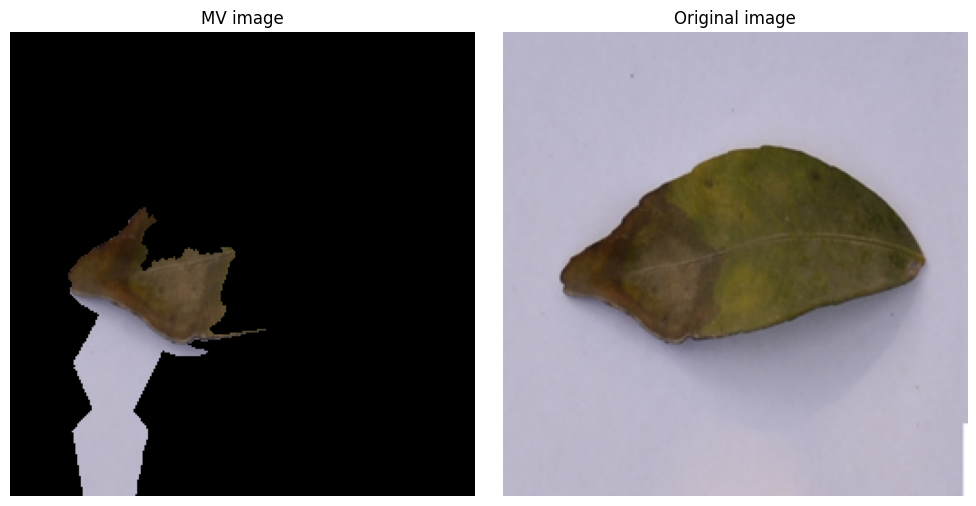


New mutation at 20 iteration
Hypervolume at 20th iteration: 1.1158


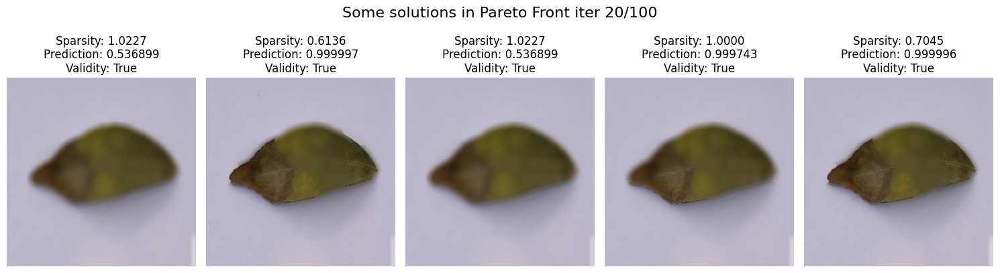

Pareto Front size: 35


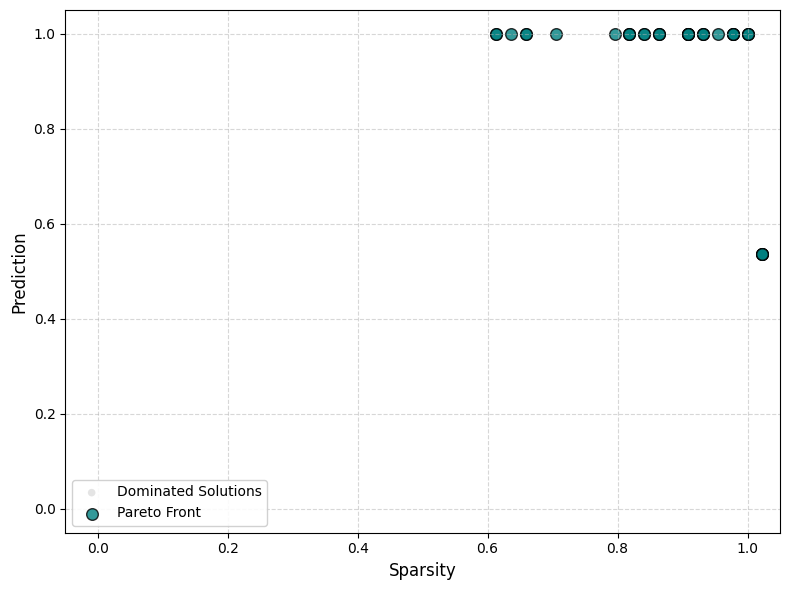

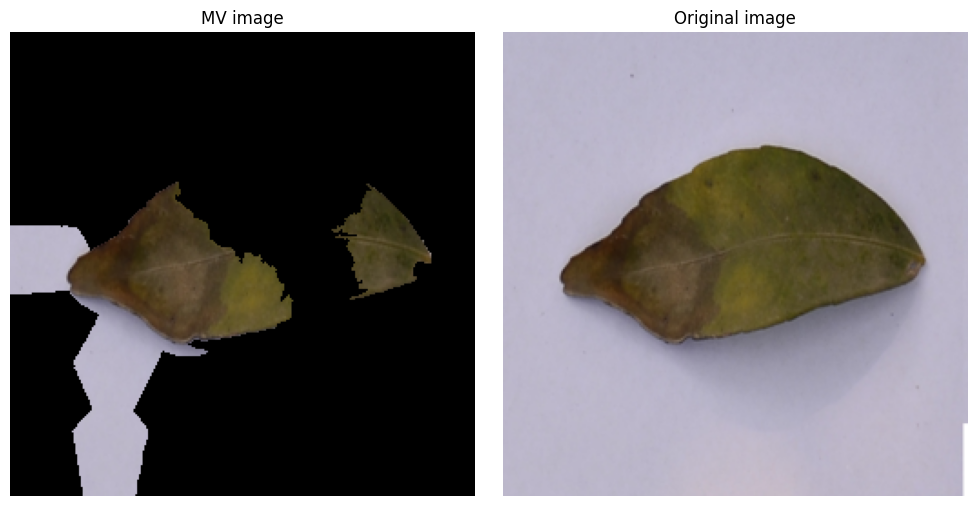


New mutation at 30 iteration
Hypervolume at 30th iteration: 1.1158


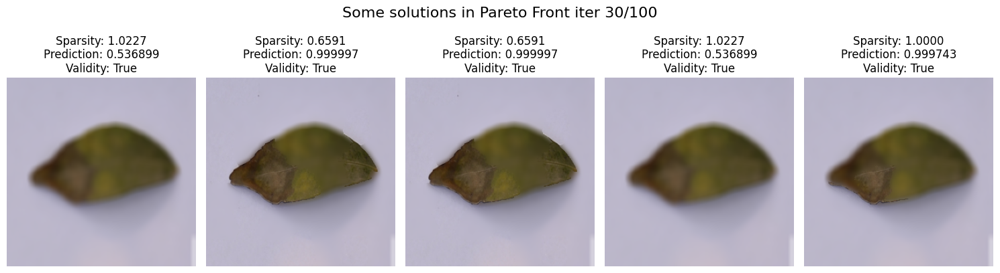

Pareto Front size: 35


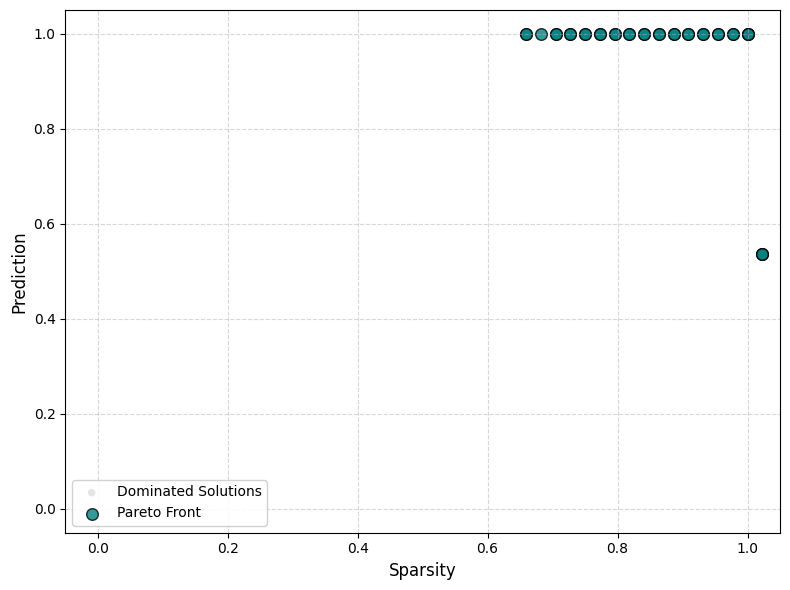

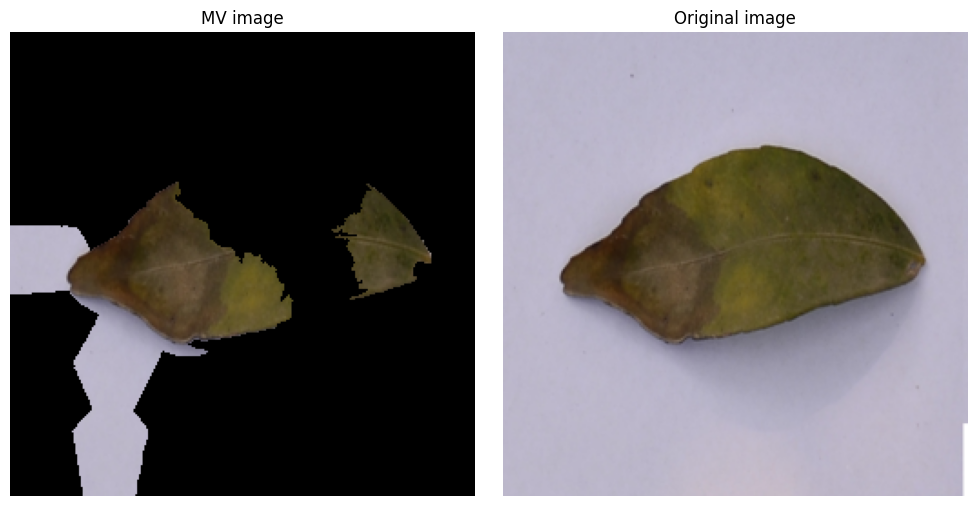


New mutation at 40 iteration
Hypervolume at 40th iteration: 1.1158


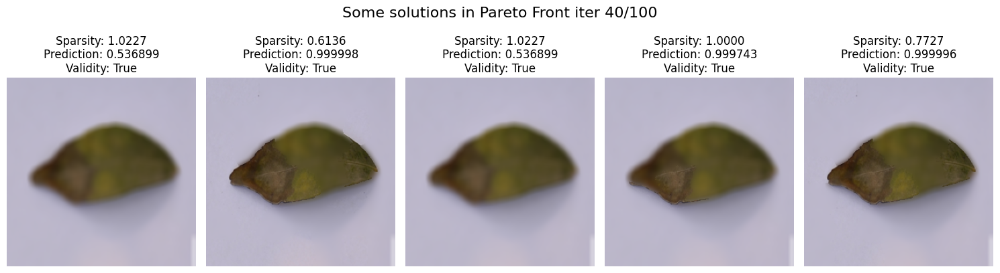

Pareto Front size: 35


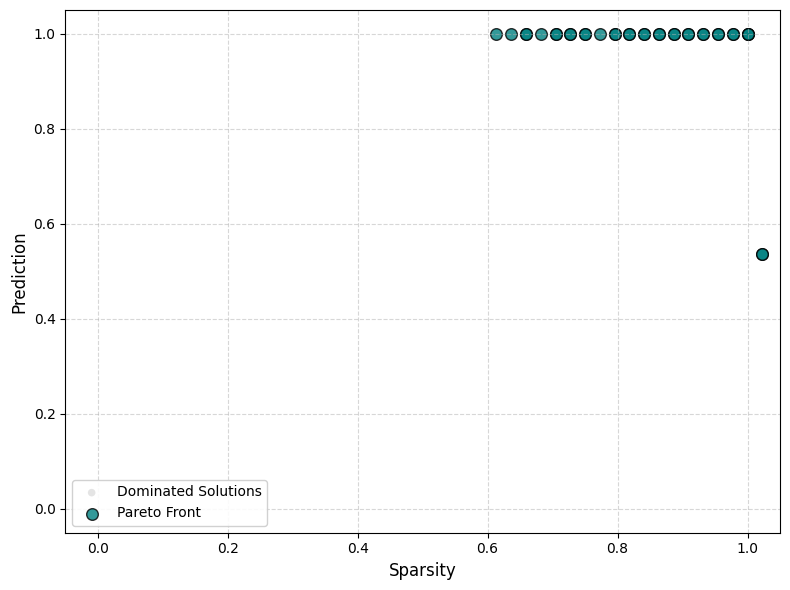

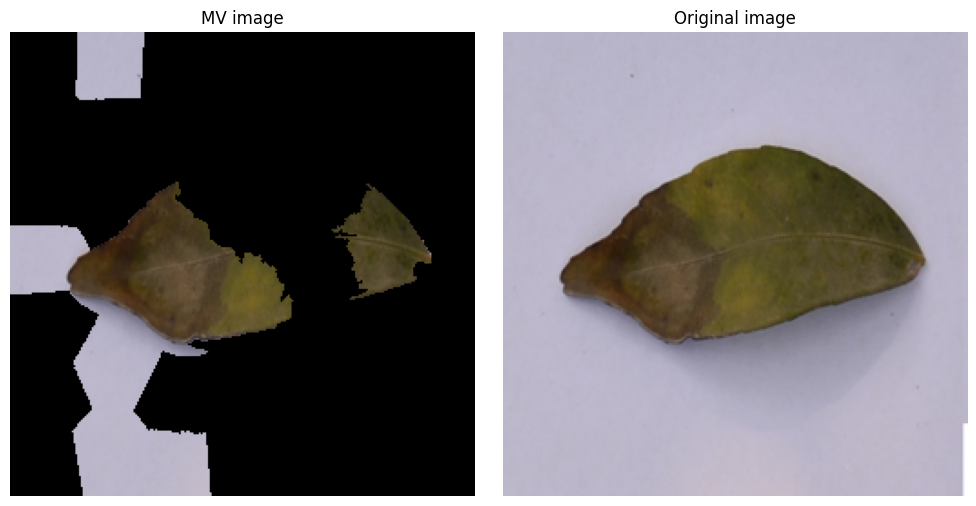


New mutation at 50 iteration
Hypervolume at 50th iteration: 1.1158


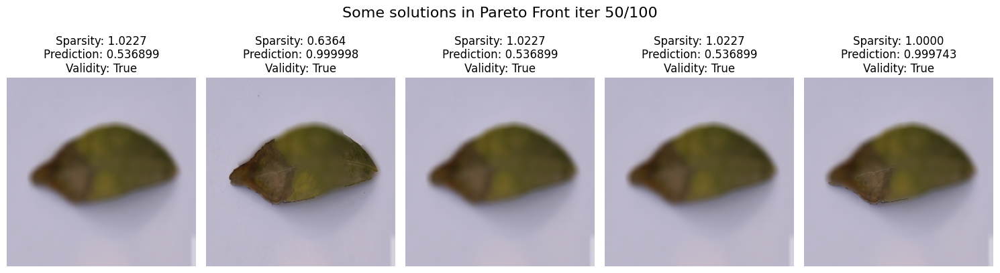

Pareto Front size: 35


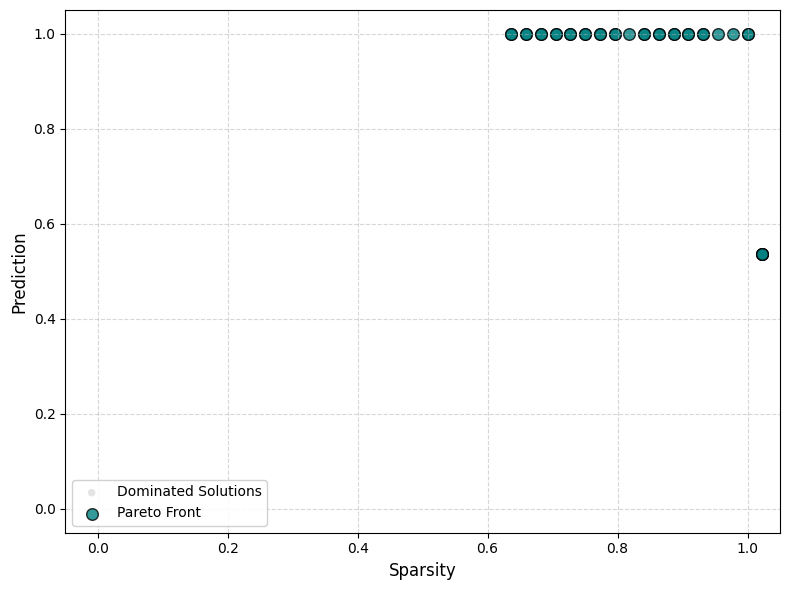

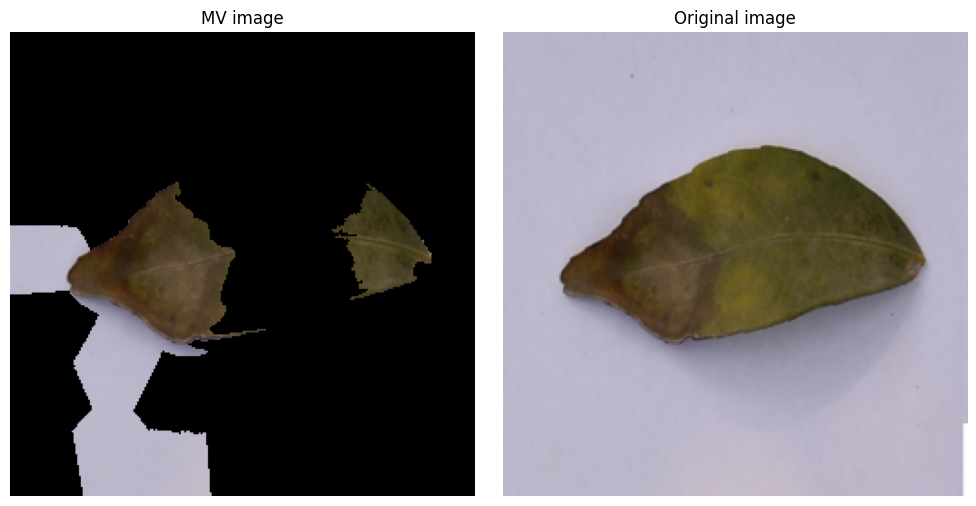


New mutation at 60 iteration
Hypervolume at 60th iteration: 1.1158


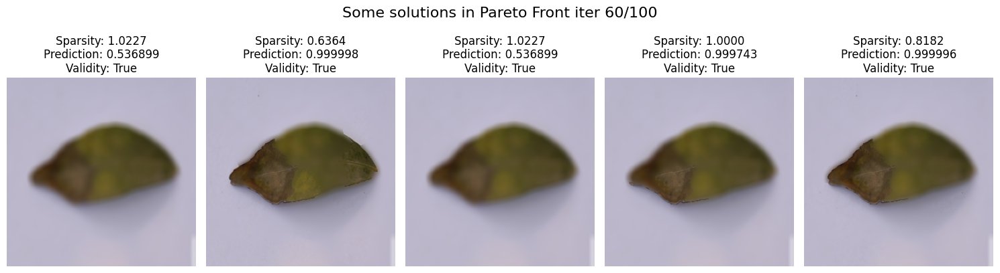

Pareto Front size: 35


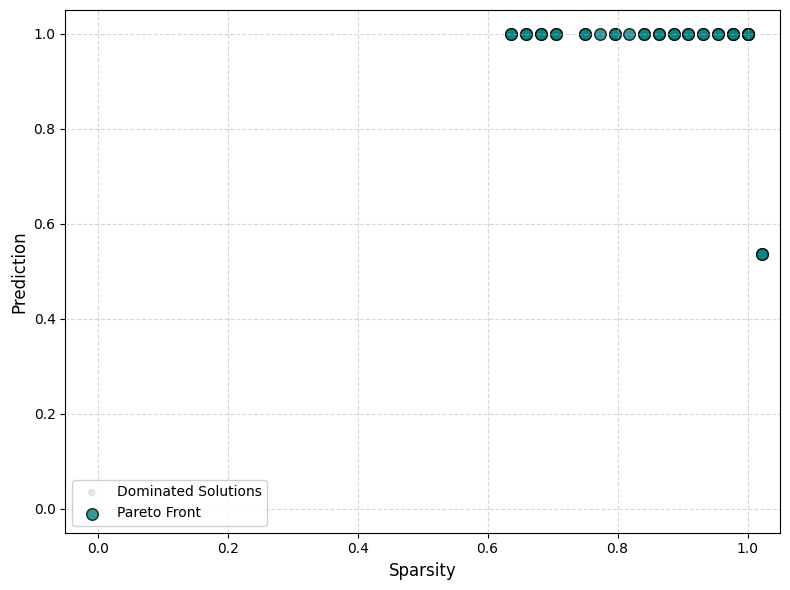

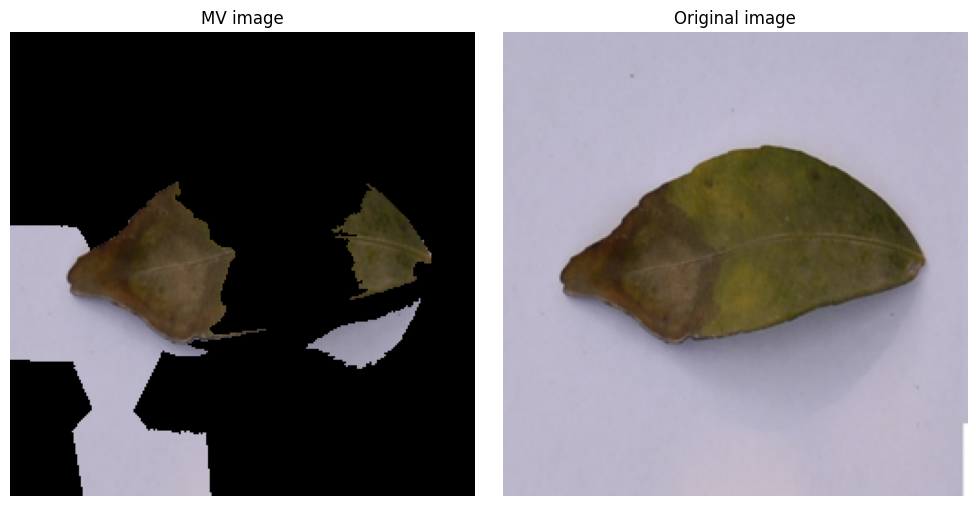


New mutation at 70 iteration
Hypervolume at 70th iteration: 1.1158


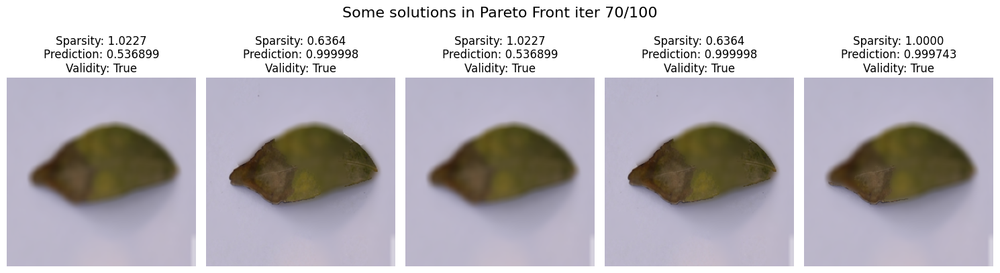

Pareto Front size: 35


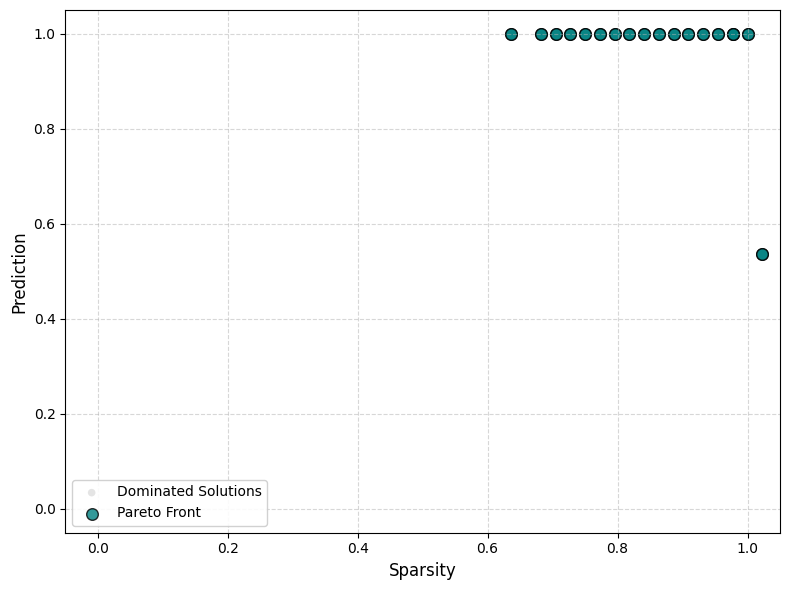

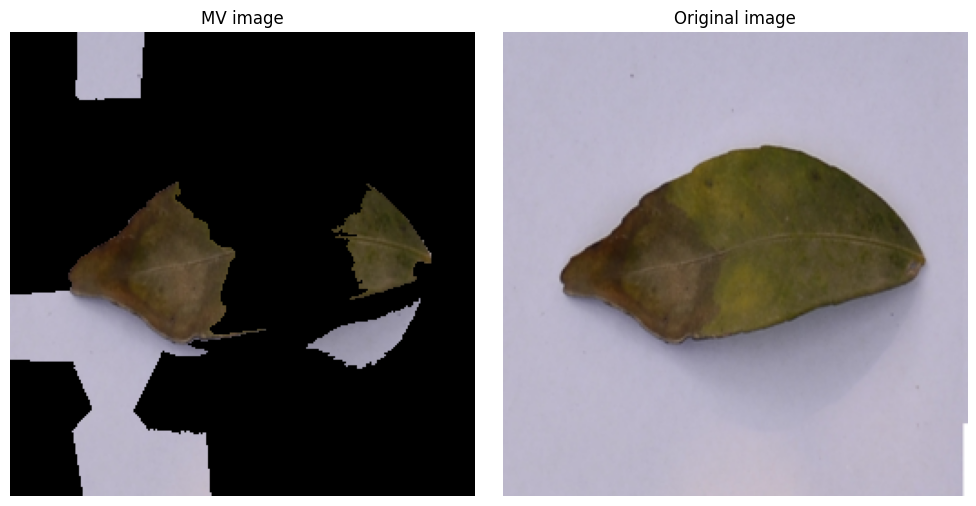


New mutation at 80 iteration
Hypervolume at 80th iteration: 1.1158


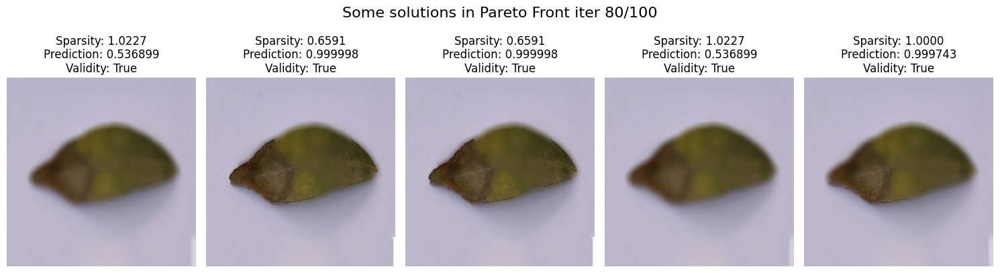

Pareto Front size: 35


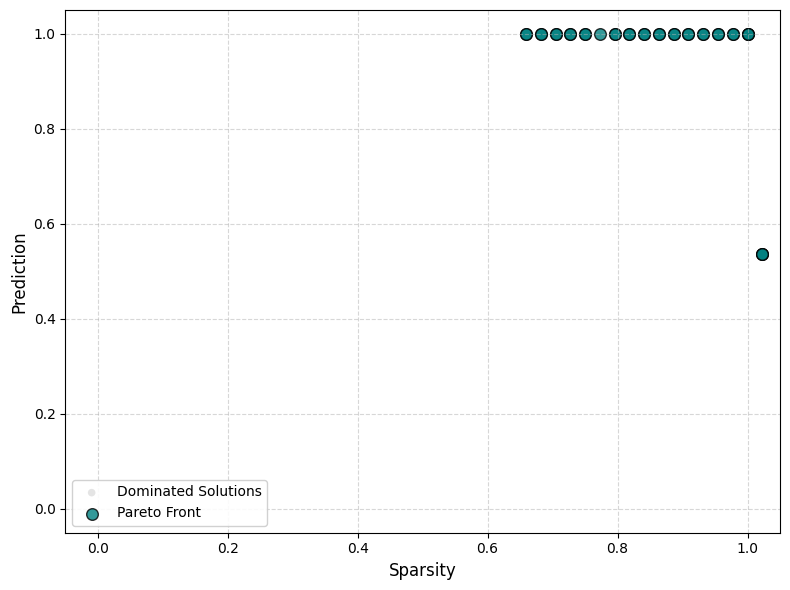

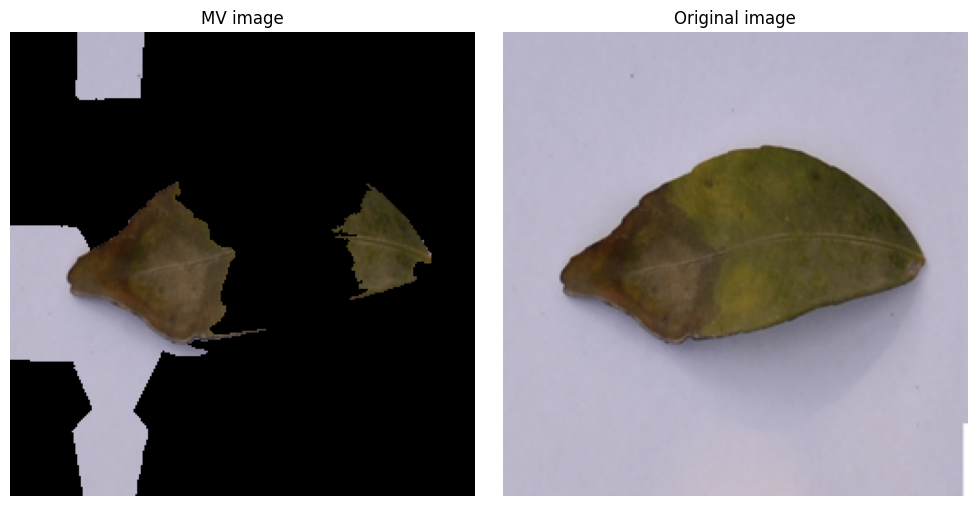


New mutation at 90 iteration
Hypervolume at 90th iteration: 1.1158


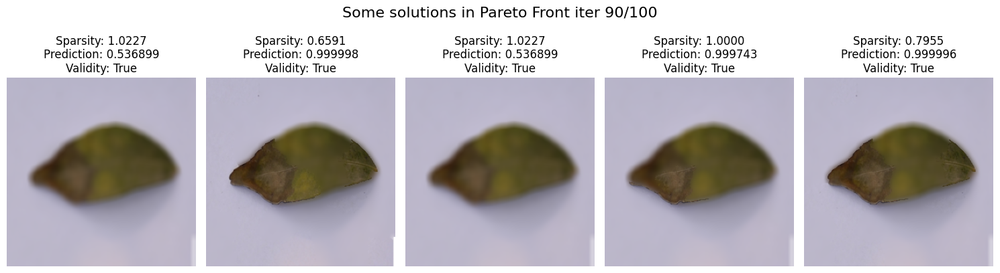

Pareto Front size: 35


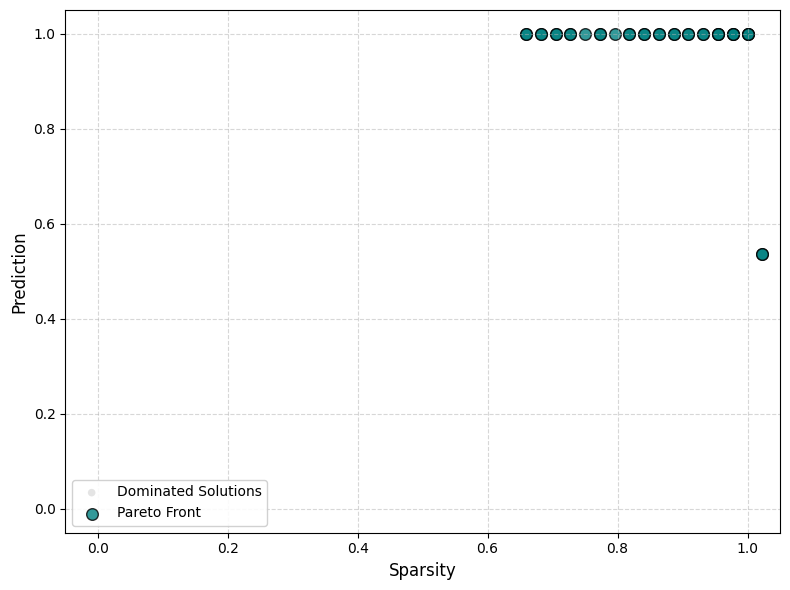

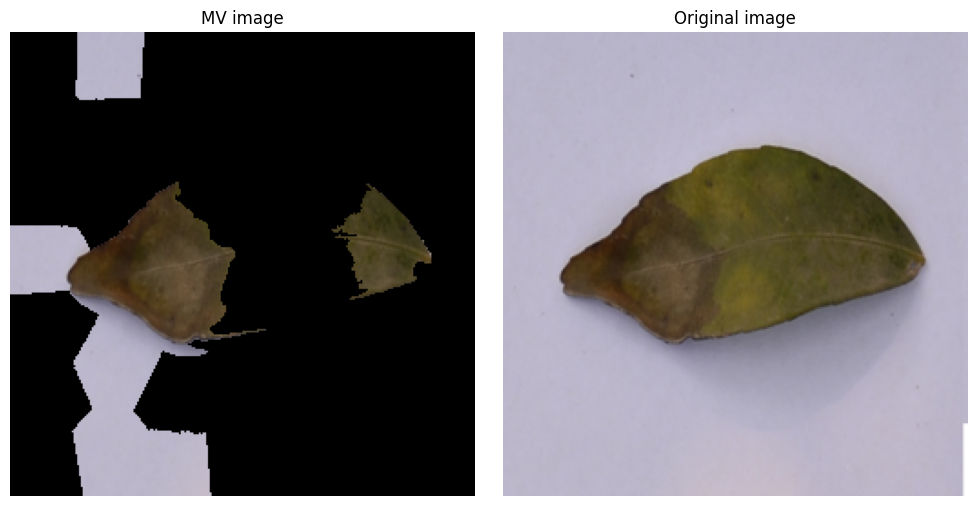


New mutation at 100 iteration
Hypervolume at 100th iteration: 1.1158


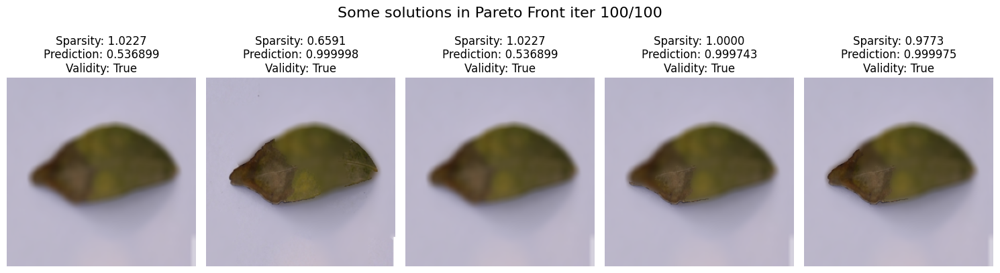

Pareto Front size: 35


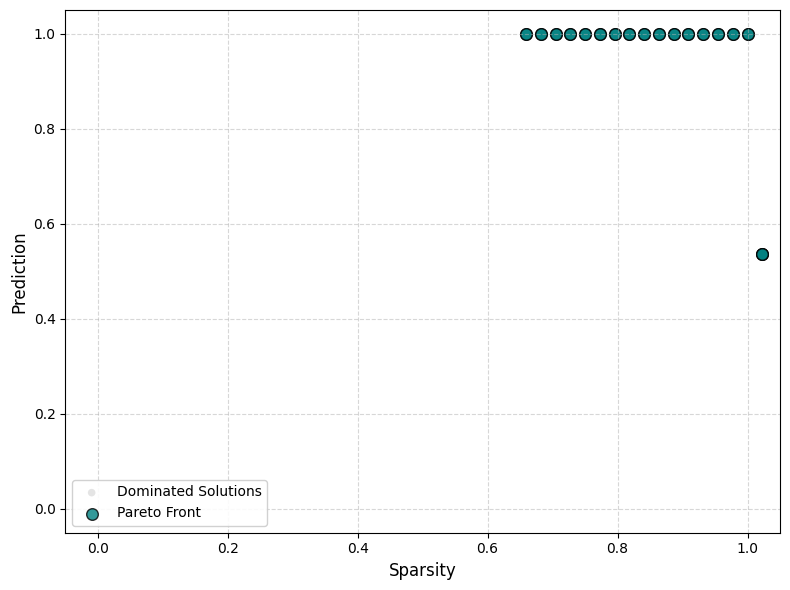

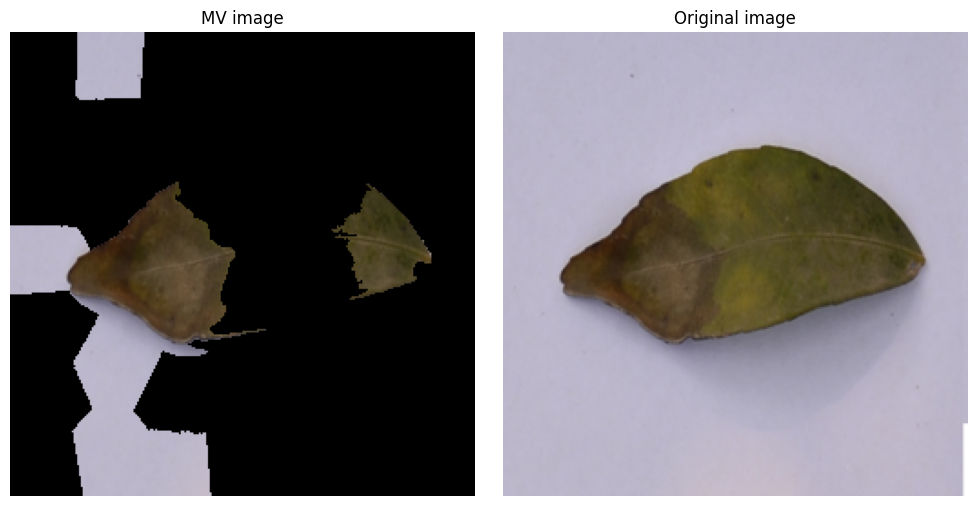

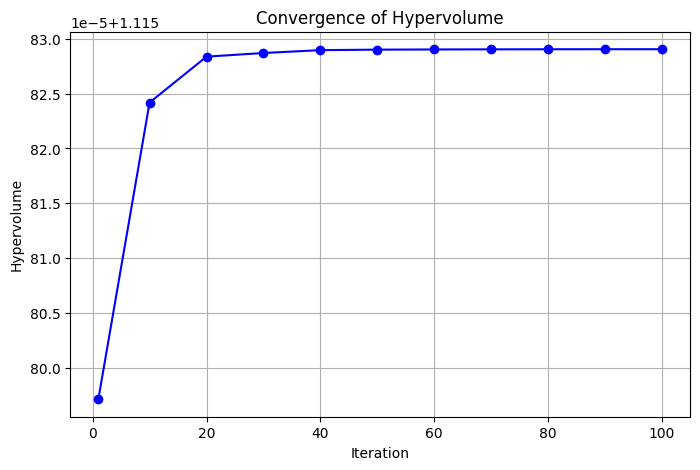

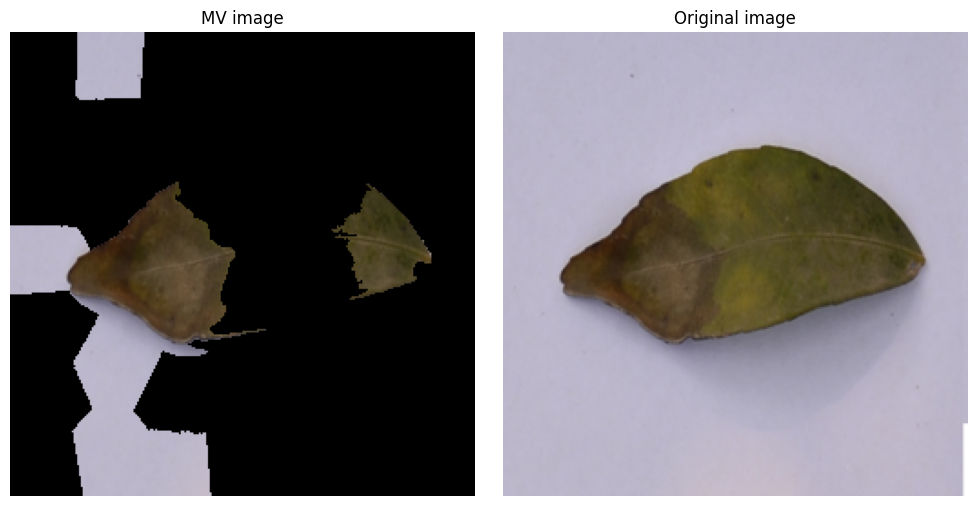

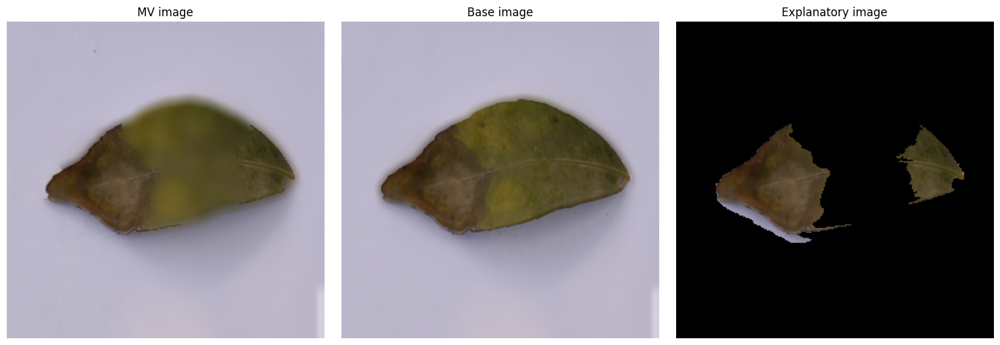

In [14]:
explanations = []
explainers = []
for _ in range(3):
    explainer = MOGAE_Explainer(predict_func, test_image, class_to_explain)
    explainer.set_optimization_hyperparameters(delta=0.09)
    explainer.run(verbose=True)

    explainers.append(explainer)
    explanations.append(explainer.explanatory_image)

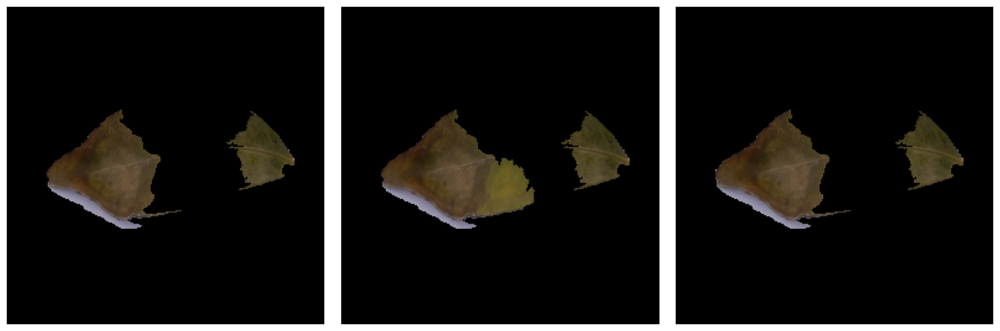

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, image in enumerate(explanations):
    ax[i].imshow(image)
    ax[i].axis("off")

plt.tight_layout()
plt.show()

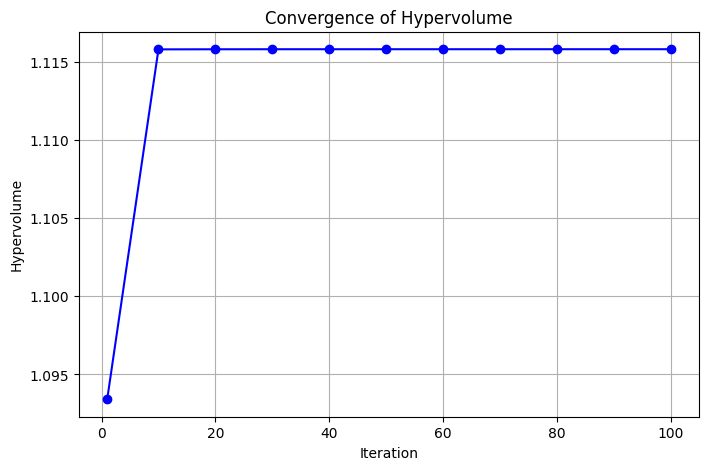

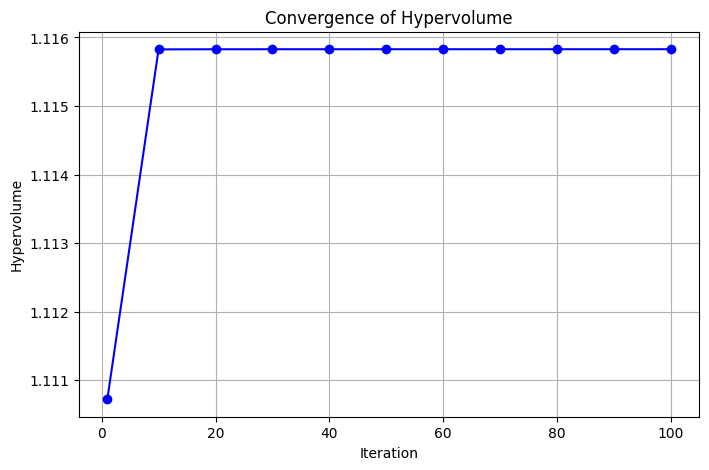

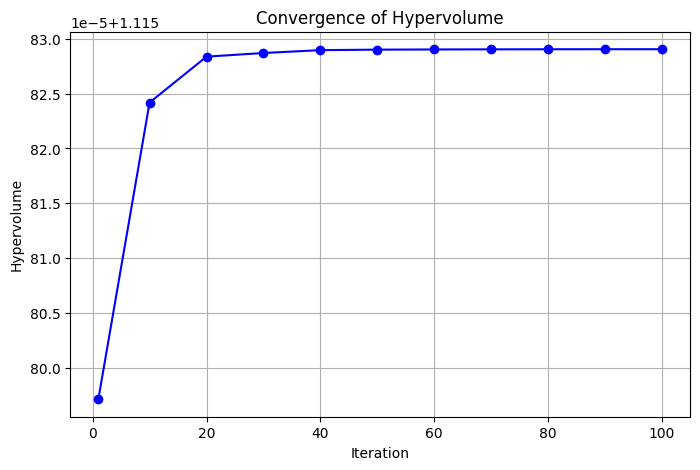

In [16]:
for i, explainer in enumerate(explainers):
    explainer.plot_hypervolume()
    plt.show()


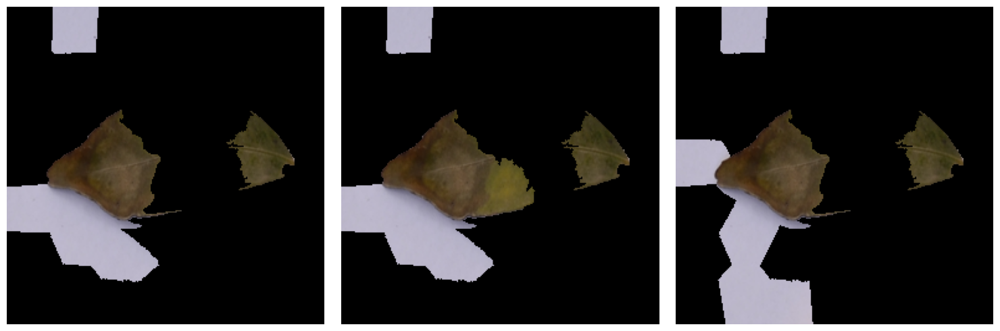

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, explainer in enumerate(explainers):
    selected_superpixels = np.where(explainer.MV_solution.Chromosome == 0)[0]
    MV_image = apply_black_color_to_superpixels(explainer.image,
                                                explainer.superpixels,
                                                selected_superpixels)
    ax[i].imshow(MV_image)
    ax[i].axis("off")

plt.tight_layout()

plt.savefig(f"{prefix}_MV.png", dpi=300, bbox_inches='tight')

plt.show()

In [18]:
def plot_paretofront(explainer, idx):
    optimal_solutions = []
    seen_chromosomes = set()

    # Remove duplicates and ValidAcc==0
    for p in explainer.ParetoFront:
        if p.ValidAcc:
            chrom_tuple = tuple(p.Chromosome)
            if chrom_tuple not in seen_chromosomes:
                optimal_solutions.append(p)
                seen_chromosomes.add(chrom_tuple)

    optimal_solutions.sort(key=lambda x: x.Fitness[0])

    n = len(optimal_solutions)
    if n < 5: num_col = 1
    else: num_col = 5
    r = n % 5
    if r!= 0: num_row = int(n / 5) + 1
    else: num_row = int(n/5)
    fig, axes = plt.subplots(num_row, num_col, figsize=(num_col*5, num_row*5))

    k = 0
    for i in range(num_row):
        for j in range(num_col):
            if k < n:
                selected_superpixels = np.where(optimal_solutions[k].Chromosome == 0)[0]
                MV_image = apply_black_color_to_superpixels(explainer.image,
                                                            explainer.superpixels,
                                                            selected_superpixels)
                axes[i, j].imshow(MV_image)
                sparsity = optimal_solutions[k].Fitness[0]
                prediction = optimal_solutions[k].Fitness[1]
                axes[i, j].set_title(f"Sparsity: {sparsity:.4f}\nPrediction: {prediction:.6f}")
                k += 1

            axes[i, j].axis("off")

    plt.tight_layout()

    plt.savefig(f"{prefix}_paretofront_{idx}.png", dpi=300, bbox_inches='tight')

    plt.show()

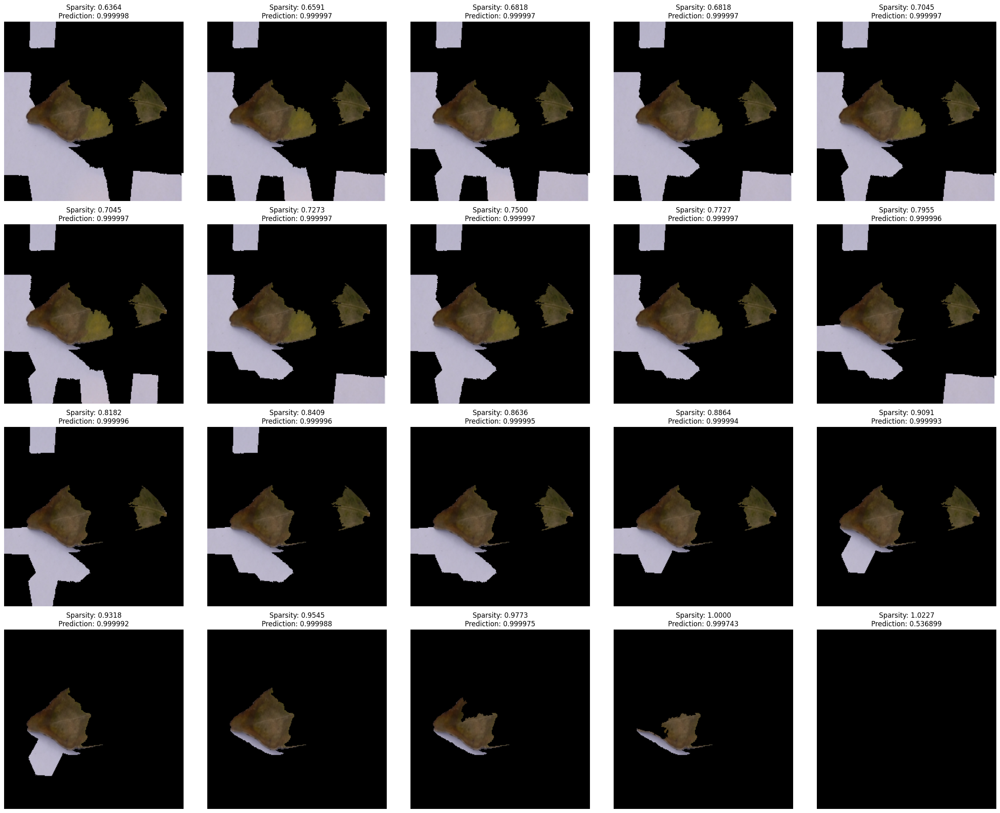

In [19]:
plot_paretofront(explainers[0], 0)

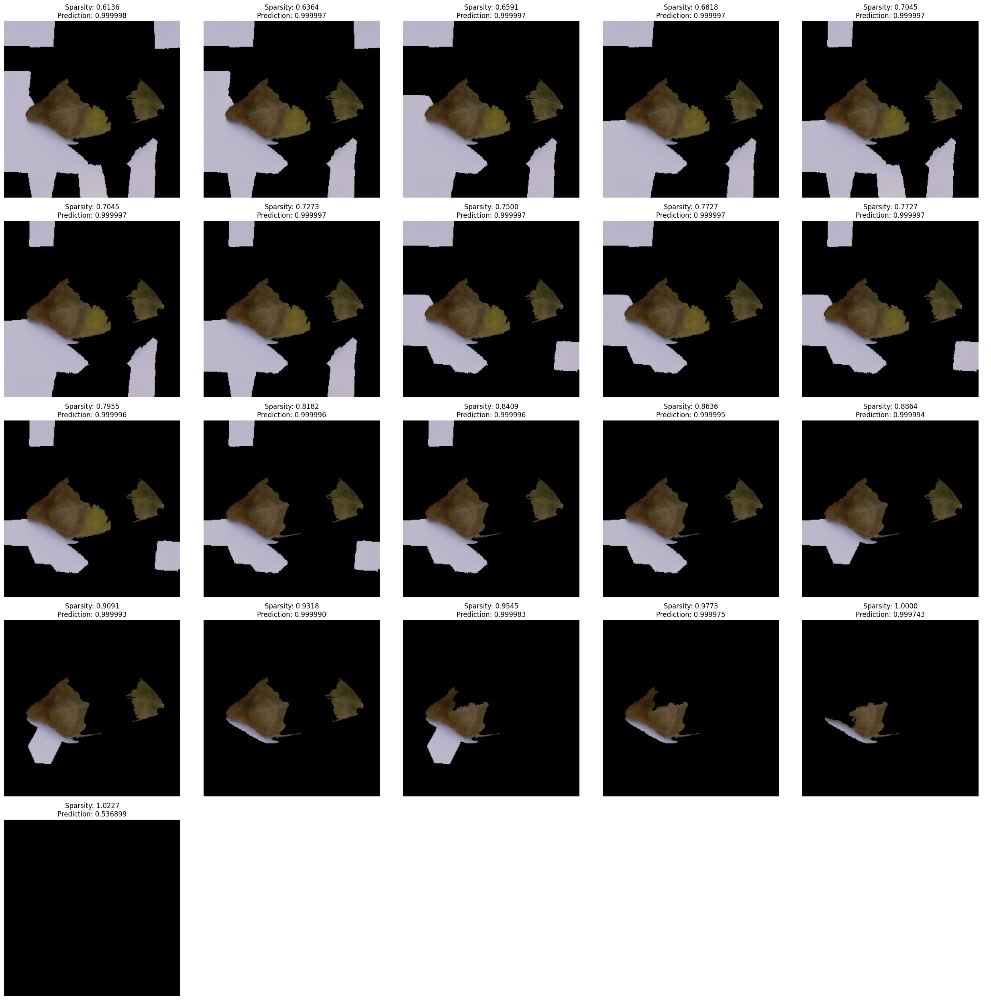

In [20]:
plot_paretofront(explainers[1], 1)

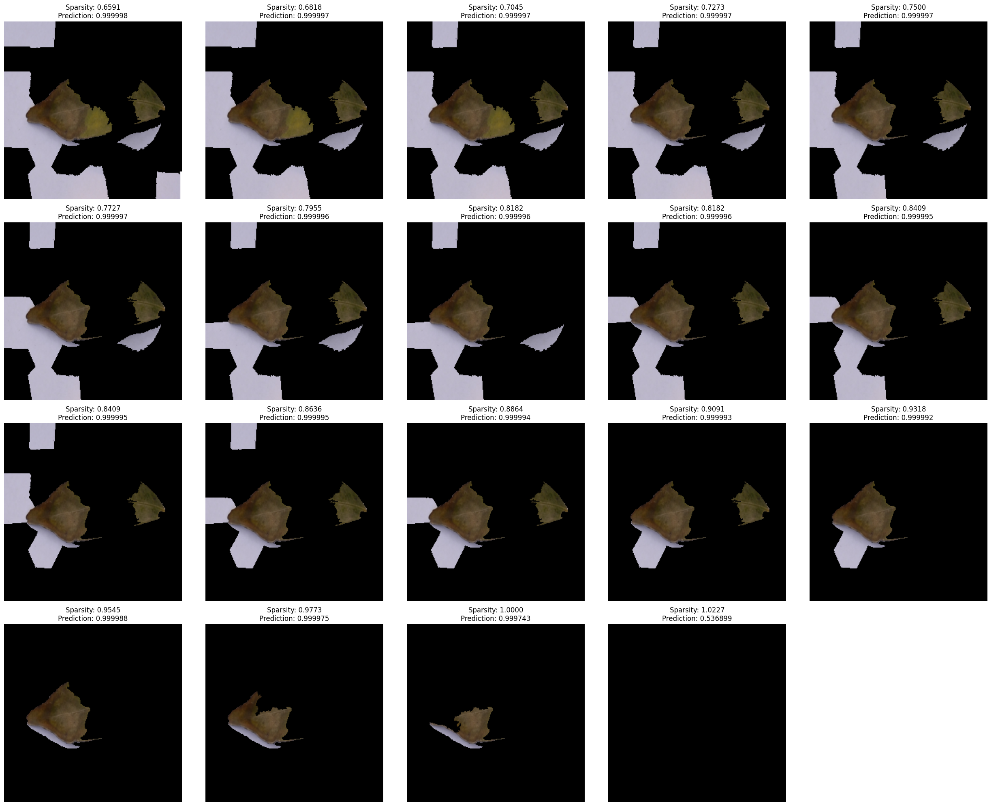

In [21]:
plot_paretofront(explainers[2], 2)

In [22]:
for i, explainer in enumerate(explainers):
    print(explainer.black_insertion_scores)
    print(explainer.black_deletion_scores)
    print(explainer.blur_insertion_scores)
    print(explainer.blur_deletion_scores)
    print()

    np.save(f"{prefix}_black_insertion_scores_{i}.npy", np.array(explainer.black_insertion_scores))
    np.save(f"{prefix}_black_deletion_scores_{i}.npy", np.array(explainer.black_deletion_scores))
    np.save(f"{prefix}_blur_insertion_scores_{i}.npy", np.array(explainer.blur_insertion_scores))
    np.save(f"{prefix}_blur_deletion_scores_{i}.npy", np.array(explainer.blur_deletion_scores))

[0.004758954048156738, 0.004758954048156738, 0.0033829212188720703, 0.00041562318801879883, 0.00041562318801879883, 0.00041562318801879883, 0.0001207590103149414, 0.0001207590103149414, 0.00041562318801879883, 0.00041562318801879883, 0.000433504581451416, 0.00041562318801879883, 0.00041562318801879883, 0.00041562318801879883, 0.00041562318801879883, 0.00041562318801879883, 0.00041562318801879883, 0.00041562318801879883, 0.0007979273796081543, 0.00014328956604003906, 0.00014328956604003906, 9.119510650634766e-05, 9.119510650634766e-05, 0.00014328956604003906, 9.119510650634766e-05, 9.119510650634766e-05, 9.119510650634766e-05, 9.119510650634766e-05, 9.119510650634766e-05, 9.500980377197266e-05, 9.119510650634766e-05, 9.119510650634766e-05, 0.00029480457305908203, 9.119510650634766e-05, 0.00029480457305908203, 0.00029480457305908203, 0.00029480457305908203, 0.00029480457305908203, 0.00029480457305908203, 0.00029480457305908203, 0.00029480457305908203, 0.00029480457305908203, 0.0002948045

In [23]:
for i, explainer in enumerate(explainers):
    print(explainer.normalized_errors)
    np.save(f"{prefix}_normalizederrors_{i}.npy", np.array(explainer.normalized_errors))

[0.12169592082500458, 0.12169592082500458, 0.11369435489177704, 0.2108016014099121, 0.2108016014099121, 0.2108016014099121, 0.2667640149593353, 0.2667640149593353, 0.2108016014099121, 0.2108016014099121, 0.27754053473472595, 0.2108016014099121, 0.2108016014099121, 0.2108016014099121, 0.2108016014099121, 0.2108016014099121, 0.2108016014099121, 0.2108016014099121, 0.10618458688259125, 0.20684795081615448, 0.20684795081615448, 0.2706632614135742, 0.2706632614135742, 0.20684795081615448, 0.2706632614135742, 0.2706632614135742, 0.2706632614135742, 0.2706632614135742, 0.2706632614135742, 0.32032671570777893, 0.2706632614135742, 0.2706632614135742, 0.27886730432510376, 0.2706632614135742, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.27886730432510376, 0.2788673043251

In [24]:
for i, explainer in enumerate(explainers):
    print(explainer.iou_scores)
    np.save(f"{prefix}_iouscores_{i}.npy", np.array(explainer.iou_scores))

[0.2854490932457518, 0.2854490932457518, 0.48153429345501214, 0.3902692707731423, 0.3902692707731423, 0.3902692707731423, 0.33818980141702426, 0.33818980141702426, 0.3902692707731423, 0.3902692707731423, 0.32669052916706975, 0.3902692707731423, 0.3902692707731423, 0.3902692707731423, 0.3902692707731423, 0.3902692707731423, 0.3902692707731423, 0.3902692707731423, 0.6244863256341221, 0.5067264573991032, 0.5067264573991032, 0.4297415894685519, 0.4297415894685519, 0.5067264573991032, 0.4297415894685519, 0.4297415894685519, 0.4297415894685519, 0.4297415894685519, 0.4297415894685519, 0.3740134091487737, 0.4297415894685519, 0.4297415894685519, 0.38275772526616464, 0.4297415894685519, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464, 0.38275772526616464,

In [25]:
!zip -q results.zip {prefix}*.png {prefix}*.npy